# Phase I (AI-aided pair): cross-modal shortcut learning in zero-shot CLIP

**Team "Four horsemen of the apocalypse"**, AI and Visualization lab, JKU Linz, WS 2026.
AI-aided pair: Mohamed Ali (k01635875), Rostislav Budarin (k12348049). The code and text were drafted with Claude (Opus 5.5) in Claude Code; the full AI interaction record is in `ai-interactions/phase1/` at the repo root.

**Model:** `openai/clip-vit-base-patch32`, zero-shot, prompts "a photo of a landbird." / "a photo of a waterbird.".
**Data:** Hugging Face `grodino/waterbirds`, split `test` (5,794 images).
**Question:** when the bird, the background and overlaid text disagree, which cue drives CLIP's answer, how strongly, and why?

**Black box only.** We use the inputs and CLIP's output logits (image-text similarities for any image and prompt). No hidden states, attention, gradients or embedding vectors are analyzed, plotted or projected (that is Phase II). Separate models are used only to describe or edit the *inputs* (rembg segmentation, OpenCV inpainting, DINOv2 as an independent image description).

**Margin:** m(x) = logit(true class) − logit(other class). m > 0 means correct. We also use the class-free *water score* s(x) = logit("waterbird") − logit("landbird"), so m = s for waterbirds and m = −s for landbirds.

Every number in the text below is printed by an executed cell. Each analysis follows **question → method → figure → finding → limitation**.

**How to run:** see `readme.md`. Heavy intermediate results (logits, masks, edited-image scores) are cached in `AIVIS_CACHE` (default `~/aivis_cache`), outside the repo. From a cold cache a full run takes about 1 h (mostly rembg on CPU); with the cache it takes a few minutes.

In [1]:
import os, sys, json, time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)
sys.path.insert(0, str(Path.cwd()))
from aivis import config, style, stats as st
from aivis.data import load_split, metadata, tern_substring_table, CLASS_NAMES
from aivis.prompts import PROMPT_PAIRS, SCENE_PROMPTS, prompt_bank, species_display
from aivis.analysis import strategy_scores, species_routing_hard, threshold_free, paired_group_diff, bank_slices

style.setup()
T0 = time.time()
def md(text):
    """Findings with numbers are rendered from executed code, never typed by hand."""
    display(Markdown(text))
pct = lambda x, d=1: f"{100*x:.{d}f}%"
print("cache:", config.CACHE_DIR, "| outputs:", config.OUT_DIR)

cache: C:\Users\medo\aivis_cache | outputs: C:\Users\medo\iCloudDrive\Downloads\Informatik\3m\vis\code_team_proj\jku-ai-visualization\Phase_1\AI Team\outputs


In [2]:
import torch
from aivis.clipscore import ClipScorer
print("torch", torch.__version__, "| CUDA available:", torch.cuda.is_available(),
      "|", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")
scorer = ClipScorer(fp16=False)   # fp32: matches the model's own forward pass to ~1e-5 (fp16: ~1e-2)

torch 2.14.1+cu126 | CUDA available: True | NVIDIA GeForce RTX 3070 Ti Laptop GPU


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

## 1. Baseline and label audit

**Question.** Does our own implementation reproduce the known zero-shot behaviour, and are the labels we score against correct?

**Method.** Score all 5,794 test images against a prompt bank of 238 prompts in one pass: the baseline pair, 3 descriptive pairs (section 3), 200 species prompts (sections 3 and 5) and 30 scene/context prompts (section 5). Only the logits are kept.

The original `generate_waterbirds.py` (group_DRO repo) marks a species as waterbird if its lowercased name contains any of 17 water category names. One of them is the substring `"tern"`, so *Eas**tern** Towhee*, *Wes**tern** Meadowlark* and *Wes**tern** Wood Pewee* (all landbirds) were labeled waterbird. We set their label to 0, keep the old one in `label_original`, and report both.

In [3]:
ds = load_split()
df = metadata(ds)
SPECIES = ds.features["bird"].names
bank = prompt_bank(SPECIES)
L = scorer.dataset_logits(ds, bank, "bank_fp32")
SL_PAIR, SL_SP, SL_SCENE = bank_slices(len(SPECIES))
print(L.shape, "logits; prompt bank =", len(PROMPT_PAIRS), "pairs +", len(SPECIES), "species +", len(SCENE_PROMPTS), "scene prompts")
print("max |our logits - model(**inputs).logits_per_image| on 16 images:",
      f"{scorer.check_equivalence(ds[:16]['image'], bank[:2]):.2e}")

df["s"] = L[:, 1] - L[:, 0]                  # water score
df["pred"] = (df["s"] > 0).astype(int)
df["margin"] = np.where(df["label"] == 1, df["s"], -df["s"])
df["margin_original"] = np.where(df["label_original"] == 1, df["s"], -df["s"])
df["correct"] = (df["pred"] == df["label"]).astype(int)
df["correct_original"] = (df["pred"] == df["label_original"]).astype(int)
display(tern_substring_table(SPECIES))
species_label = df.groupby("species_id")["label"].first().reindex(range(len(SPECIES))).to_numpy()
print("species with corrected label 1:", int(species_label.sum()), "| tern-bug images:", int(df.tern_bug.sum()))

(5794, 238) logits; prompt bank = 4 pairs + 200 species + 30 scene prompts


max |our logits - model(**inputs).logits_per_image| on 16 images: 5.72e-06


,species,is_real_tern
0,Eastern_Towhee,False
1,Western_Grebe,False
2,Western_Gull,False
3,Western_Meadowlark,False
4,Western_Wood_Pewee,False
5,Artic_Tern,True
6,Black_Tern,True
7,Caspian_Tern,True
8,Common_Tern,True
9,Elegant_Tern,True


species with corrected label 1: 43 | tern-bug images: 90


In [4]:
# CIs resample whole species (after the critique at check-in 5): images of one species are not independent.
rows = []
for which, lab, grp, cor in [("original labels", "label_original", "group_original", "correct_original"),
                             ("corrected labels", "label", "group", "correct")]:
    e = st.cluster_boot_mean(df[cor].to_numpy(float), df.species)
    rows.append(dict(labels=which, group="overall", n=len(df), acc=e[0], lo=e[1], hi=e[2]))
    for g in style.GROUPS:
        sub = df[df[grp] == g]
        e = st.cluster_boot_mean(sub[cor].to_numpy(float), sub.species)
        rows.append(dict(labels=which, group=g, n=len(sub), acc=e[0], lo=e[1], hi=e[2]))
acc_tab = pd.DataFrame(rows)
display(acc_tab.assign(**{"accuracy [95% CI]": [st.fmt_ci(a, l, h, pct=True) for a, l, h in zip(acc_tab.acc, acc_tab.lo, acc_tab.hi)]})
        [["labels", "group", "n", "accuracy [95% CI]"]])

err_o = df[df.correct_original == 0]
bug_err = err_o.groupby("group_original").tern_bug.agg(["size", "sum"]).rename(columns={"size": "errors", "sum": "of which tern-bug species"})
display(bug_err)
expected = {"overall": .706, "landbird / land": .876, "landbird / water": .451, "waterbird / land": .749, "waterbird / water": .960}
chk = acc_tab[acc_tab.labels == "original labels"].set_index("group").acc
print("reproduction check (ours - expected, pp):", {g: round(100 * (chk[g] - v), 2) for g, v in expected.items()})

,labels,group,n,accuracy [95% CI]
0,original labels,overall,5794,"70.6% [68.0, 73.1]"
1,original labels,landbird / land,2255,"87.5% [84.8, 89.9]"
2,original labels,landbird / water,2255,"45.1% [41.5, 48.6]"
3,original labels,waterbird / land,642,"74.9% [68.5, 80.5]"
4,original labels,waterbird / water,642,"96.0% [91.9, 99.2]"
5,corrected labels,overall,5794,"71.0% [68.5, 73.4]"
6,corrected labels,landbird / land,2298,"87.5% [84.9, 89.8]"
7,corrected labels,landbird / water,2302,"45.1% [41.5, 48.6]"
8,corrected labels,waterbird / land,599,"79.3% [75.0, 83.5]"
9,corrected labels,waterbird / water,595,"99.2% [98.2, 99.8]"


,errors,of which tern-bug species
group_original,,
landbird / land,281,0
landbird / water,1238,0
waterbird / land,161,37
waterbird / water,26,21


reproduction check (ours - expected, pp): {'overall': np.float64(-0.04), 'landbird / land': np.float64(-0.06), 'landbird / water': np.float64(-0.0), 'waterbird / land': np.float64(0.02), 'waterbird / water': np.float64(-0.05)}


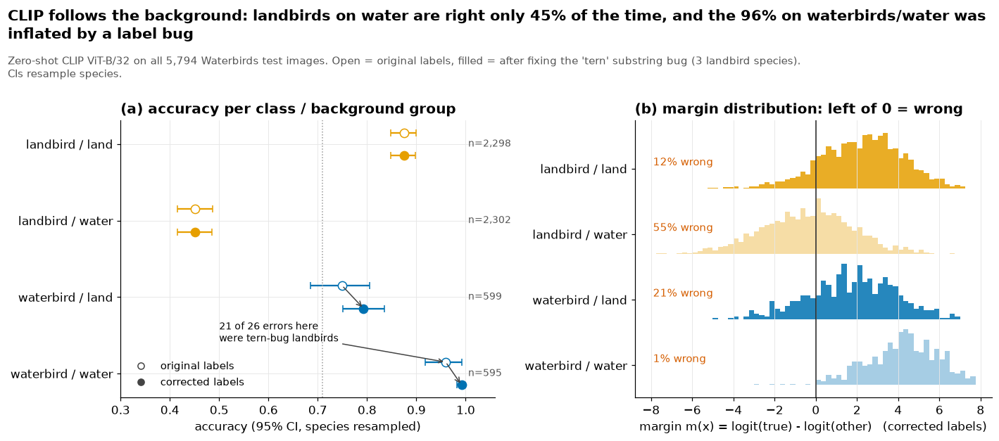

In [5]:
fig, (ax, bx) = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw=dict(width_ratios=[1.05, 1]))
groups = style.GROUPS
for i, g in enumerate(groups):
    o = acc_tab[(acc_tab.labels == "original labels") & (acc_tab.group == g)].iloc[0]
    c = acc_tab[(acc_tab.labels == "corrected labels") & (acc_tab.group == g)].iloc[0]
    col = style.GROUP_COLOR[g]
    yy = len(groups) - 1 - i
    ax.errorbar(o.acc, yy + 0.15, xerr=[[o.acc - o.lo], [o.hi - o.acc]], fmt="o", mfc="white", mec=col, ecolor=col, ms=8, capsize=3)
    ax.errorbar(c.acc, yy - 0.15, xerr=[[c.acc - c.lo], [c.hi - c.acc]], fmt="o", mfc=col, mec=col, ecolor=col, ms=8, capsize=3)
    if abs(c.acc - o.acc) > 0.005:
        ax.annotate("", xy=(c.acc, yy - 0.15), xytext=(o.acc, yy + 0.15), arrowprops=dict(arrowstyle="->", color="#444", lw=1))
    ax.text(1.005, yy, f"n={c.n:,}", va="center", fontsize=9, color="#555")
ax.set_yticks(range(len(groups)), [g for g in groups[::-1]])
ax.set_xlim(0.3, 1.06); ax.set_xlabel("accuracy (95% CI, species resampled)")
ax.axvline(acc_tab.query("labels=='corrected labels' and group=='overall'").acc.iloc[0], color="#999", ls=":", lw=1)
ax.plot([], [], "o", mfc="white", mec="#444", label="original labels"); ax.plot([], [], "o", mfc="#444", mec="#444", label="corrected labels")
ax.legend(loc="lower left"); ax.set_title("(a) accuracy per class / background group")
wb_err = bug_err.loc["waterbird / water"]
ax.annotate(f"{int(wb_err.iloc[1])} of {int(wb_err.iloc[0])} errors here\nwere tern-bug landbirds",
            xy=(acc_tab.query("labels=='original labels' and group=='waterbird / water'").acc.iloc[0], 0.15),
            xytext=(0.5, 0.42), fontsize=9, arrowprops=dict(arrowstyle="->", color="#444"))
# (b) margin distributions
bins = np.linspace(-8, 8, 65)
for i, g in enumerate(groups):
    m = df.loc[df.group == g, "margin"]
    h, _ = np.histogram(m, bins=bins, density=True)
    yy = len(groups) - 1 - i
    bx.fill_between(bins[:-1], yy, yy + h / h.max() * 0.85, step="post", color=style.GROUP_COLOR[g],
                    alpha=0.85 if style.GROUP_FILLED[g] else 0.35, lw=0)
    bx.text(-7.9, yy + 0.35, f"{pct((m < 0).mean(), 0)} wrong", ha="left", fontsize=9.5, color=style.ERROR)
bx.axvline(0, color="#222", lw=1); bx.set_yticks(np.arange(len(groups)) + 0.3, groups[::-1])
bx.set_xlabel("margin m(x) = logit(true) - logit(other)   (corrected labels)")
bx.set_title("(b) margin distribution: left of 0 = wrong"); bx.grid(axis="y", visible=False)
lbw = acc_tab.query("labels=='corrected labels' and group=='landbird / water'").acc.iloc[0]
fig.tight_layout()
style.suptitle(fig, f"CLIP follows the background: landbirds on water are right only {pct(lbw, 0)} of the time, "
               f"and the 96% on waterbirds/water was inflated by a label bug",
               "Zero-shot CLIP ViT-B/32 on all 5,794 Waterbirds test images. Open = original labels, filled = after fixing the 'tern' substring bug (3 landbird species). CIs resample species.")
style.save(fig, "fig1_baseline_label_audit"); plt.show()

In [6]:
lb_l, lb_w, wb_l, wb_w = [acc_tab.query("labels=='corrected labels' and group==@g").iloc[0] for g in groups]
o_wbw = acc_tab.query("labels=='original labels' and group=='waterbird / water'").iloc[0]
md(f"""**Finding.** The reproduction matches (overall {pct(chk['overall'])} vs. 70.6% expected). The background drives the errors:
with corrected labels, landbirds are right {pct(lb_l.acc)} of the time on land but only {pct(lb_w.acc)} [{pct(lb_w.lo)}, {pct(lb_w.hi)}] on water, and waterbirds {pct(wb_w.acc)} on water but {pct(wb_l.acc)} on land.
The label bug matters for the waterbird groups. {int(wb_err.iloc[1])} of the {int(wb_err.iloc[0])} waterbird/water errors and {int(bug_err.loc['waterbird / land'].iloc[1])} of the {int(bug_err.loc['waterbird / land'].iloc[0])} waterbird/land errors were tern-bug landbirds that CLIP had correctly called *landbird*.
After the fix, waterbird/water goes from {pct(o_wbw.acc)} to {pct(wb_w.acc)}. The {int(df.tern_bug.sum())} tern-bug images move into the landbird groups, where CLIP calls {pct(df.loc[df.tern_bug, 'pred'].mean())} of them waterbird.""")

**Finding.** The reproduction matches (overall 70.6% vs. 70.6% expected). The background drives the errors:
with corrected labels, landbirds are right 87.5% of the time on land but only 45.1% [41.5%, 48.6%] on water, and waterbirds 99.2% on water but 79.3% on land.
The label bug matters for the waterbird groups. 21 of the 26 waterbird/water errors and 37 of the 161 waterbird/land errors were tern-bug landbirds that CLIP had correctly called *landbird*.
After the fix, waterbird/water goes from 96.0% to 99.2%. The 90 tern-bug images move into the landbird groups, where CLIP calls 35.6% of them waterbird.

**Limitation.** Accuracy at the default threshold mixes two things: a constant preference for one class (the threshold) and the background effect. Section 3 separates them with threshold-free AUCs. The label audit only covers the "tern" rule. Other definitional choices of the original script (e.g. kingfishers counted as landbirds) are analyzed in section 2, not "fixed".

## 2. Species water association: label definition vs. background shortcut

**Question.** The dataset's waterbird/landbird split is a *rule on species names* (17 seabird/waterfowl families). Ecologically, kingfishers, marsh blackbirds or waterthrushes live at the water too, but they count as landbirds. How many of CLIP's "errors" are really disagreements about the label definition, and how many are a genuine background shortcut?

**Method.** A GenAI-derived attribute (Lab 03, "GenAI as a tool to transform your data"): every species is rated 0-3 for how tied it is to water habitats, plus a one-line reason (`species_water_rating.csv`).
- **Raters:** 4 independent AI raters, all with the same written rubric. A = Claude Opus 5.5, B = Sonnet 5.5, C = Haiku 5.5, D = Opus with a "describe the habitat first, then rate" prompt.
- **Final rating:** the value at least 3 of the 4 raters agree on; otherwise an adjudicator agent decides. A critic agent flagged inconsistencies; its flags are recorded, not applied.
- **Blinding:** the raters never saw CLIP outputs or dataset labels. The prompts are logged verbatim in `ai-interactions/phase1/03_species_ratings.md`.
- **Reliability:** agreement between the AI raters (consistency only), and a **blind human check** of 40 species against Wikipedia or a field guide (`species_water_handcheck.csv`, filled in by us).

In [7]:
from sklearn.metrics import cohen_kappa_score
rat = pd.read_csv("species_water_rating.csv")
rat["label"] = rat.species.map(df.groupby("species").label.first())
df = df.merge(rat[["species", "water_rating"]], on="species", how="left")
assert df.water_rating.notna().all() and (df.idx.to_numpy() == np.arange(len(df))).all()  # row order = logits order

pairs = [("A", "B"), ("A", "C"), ("A", "D"), ("B", "C"), ("B", "D"), ("C", "D")]
agree = pd.DataFrame([dict(pair=f"{a}-{b}", exact=(rat[f"rating_{a}"] == rat[f"rating_{b}"]).mean(),
                           within1=((rat[f"rating_{a}"] - rat[f"rating_{b}"]).abs() <= 1).mean(),
                           kappa_w=cohen_kappa_score(rat[f"rating_{a}"], rat[f"rating_{b}"], weights="quadratic"))
                      for a, b in pairs])
display(agree.round(3))
print("final rating source:", rat.source.value_counts().to_dict())
print("ratings x dataset label:\n", pd.crosstab(rat.water_rating, rat.label.map({0: "landbird", 1: "waterbird"})))

hc = pd.read_csv("species_water_handcheck.csv")
hc = hc.merge(rat[["species", "water_rating"]], on="species")
filled = hc[pd.to_numeric(hc.human_rating, errors="coerce").notna()].copy()
if len(filled):
    filled["human_rating"] = filled.human_rating.astype(int)
    hc_stats = dict(n=len(filled), exact=(filled.human_rating == filled.water_rating).mean(),
                    within1=((filled.human_rating - filled.water_rating).abs() <= 1).mean(),
                    kappa_w=cohen_kappa_score(filled.human_rating, filled.water_rating, weights="quadratic"))
    md(f"**Human check:** {hc_stats['n']} species checked; exact agreement {pct(hc_stats['exact'])}, within ±1 {pct(hc_stats['within1'])}, "
       f"quadratic-weighted κ = {hc_stats['kappa_w']:.2f}.")
    display(filled[filled.human_rating != filled.water_rating][["species", "water_rating", "human_rating", "source_used", "notes"]])
else:
    hc_stats = None
    md(f"**Human check: pending.** 0 of {len(hc)} species in `species_water_handcheck.csv` have a `human_rating` yet. "
       "Until it is filled in, the ratings are only checked for consistency between AI raters, not for correctness.")

,pair,exact,within1,kappa_w
0,A-B,0.940,1.0,0.981
1,A-C,0.885,1.0,0.963
2,A-D,0.975,1.0,0.992
3,B-C,0.885,1.0,0.963
4,B-D,0.935,1.0,0.979
5,C-D,0.910,1.0,0.971


final rating source: {'consensus': 193, 'adjudicated': 7}
ratings x dataset label:
 label         landbird  waterbird
water_rating                     
0                  111          0
1                   26          0
2                   15          0
3                    5         43


**Human check: pending.** 0 of 40 species in `species_water_handcheck.csv` have a `human_rating` yet. Until it is filled in, the ratings are only checked for consistency between AI raters, not for correctness.

**Unit of analysis.** The rating is a property of the *species*, and errors cluster by species (Pied Kingfisher is 94% wrong on land, Seaside Sparrow 0%). So all CIs below resample whole species, not images, and the main test is a **species-level permutation test**: the ratings are shuffled across the 157 landbird species (10,000 times), and the observed difference in species-mean error is compared with that null. This replaced an image-level bootstrap after the critique at check-in 5 (its CIs were too narrow).

In [8]:
df["err"] = 1 - df["correct"]
LB = df[df.label == 0]
sp_stats = (df.groupby(["species", "place_name"])
              .agg(n=("correct", "size"), err=("err", "mean"), label=("label", "first"),
                   rating=("water_rating", "first"), bug=("tern_bug", "first"))
              .reset_index())
rng = np.random.default_rng(0)
sp_stats["xj"] = sp_stats.rating + rng.uniform(-0.18, 0.18, len(sp_stats)) + np.where(sp_stats.label == 1, 0.06, -0.06)

def rate_ci(d):
    """Error rate of an image subset with a species-cluster bootstrap CI."""
    return st.cluster_boot_mean(d.err.to_numpy(float), d.species)

rows = []
for place in ("land", "water"):
    for r in (0, 1, 2, 3):
        d = LB[(LB.place_name == place) & (LB.water_rating == r)]
        e = rate_ci(d)
        rows.append(dict(background=place, rating=str(r), species=d.species.nunique(), images=len(d), err=e[0], lo=e[1], hi=e[2]))
    d = LB[(LB.place_name == place) & (LB.water_rating >= 2) & ~LB.species.str.contains("Kingfisher")]
    e = rate_ci(d)
    rows.append(dict(background=place, rating="≥2 without kingfishers", species=d.species.nunique(), images=len(d), err=e[0], lo=e[1], hi=e[2]))
lb_rates = pd.DataFrame(rows)
display(lb_rates.assign(err=lambda t: (100 * t.err).round(1), lo=lambda t: (100 * t.lo).round(1), hi=lambda t: (100 * t.hi).round(1)))

perm_rng = np.random.default_rng(1)
perm_rows = []
for place in ("land", "water"):
    sp = LB[LB.place_name == place].groupby("species").agg(e=("err", "mean"), r=("water_rating", "first"))
    for lev in (2, 3):
        obs = sp.e[sp.r == lev].mean() - sp.e[sp.r == 0].mean()
        null = np.empty(10000)
        for k in range(10000):
            rr = perm_rng.permutation(sp.r.to_numpy())
            null[k] = sp.e.to_numpy()[rr == lev].mean() - sp.e.to_numpy()[rr == 0].mean()
        perm_rows.append(dict(background=place, rating=lev, n_species=int((sp.r == lev).sum()), diff_vs_rating0=obs,
                              p_value=(np.sum(np.abs(null) >= abs(obs)) + 1) / (len(null) + 1)))
perm = pd.DataFrame(perm_rows)
display(perm.round(4))
PV = perm.set_index(["background", "rating"]).p_value
LR = lb_rates.set_index(["background", "rating"])

,background,rating,species,images,err,lo,hi
0,land,0,111,1640,11.8,9.6,14.2
1,land,1,26,371,10.0,4.5,17.2
2,land,2,15,210,9.0,3.7,14.1
3,land,3,5,77,49.4,26.3,75.3
4,land,≥2 without kingfishers,16,225,9.8,4.5,14.9
5,water,0,111,1603,53.0,49.0,57.1
6,water,1,26,398,52.0,43.1,61.4
7,water,2,15,228,63.6,53.2,74.2
8,water,3,5,73,84.9,71.6,95.4
9,water,≥2 without kingfishers,16,243,63.4,53.1,73.0


,background,rating,n_species,diff_vs_rating0,p_value
0,land,2,15,-0.0350,0.3989
1,land,3,5,0.3574,0.0001
2,water,2,15,0.1114,0.0824
3,water,3,5,0.3198,0.0017


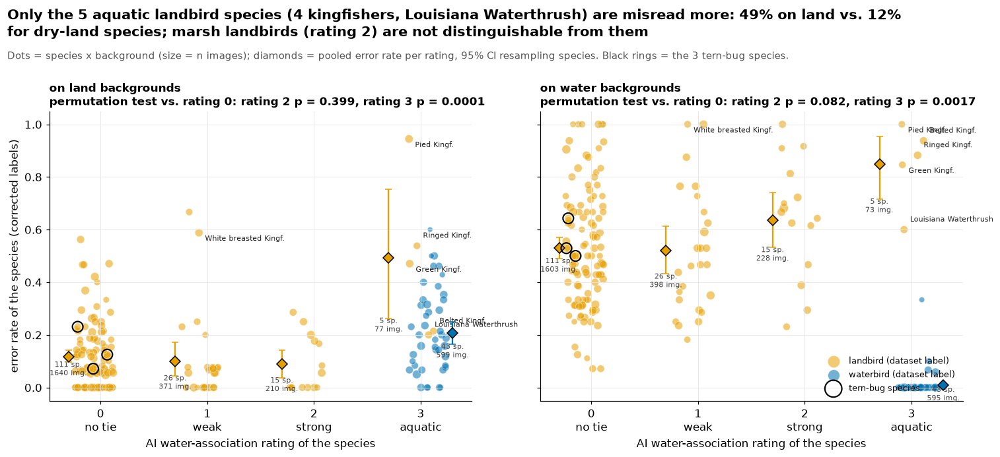

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.4), sharey=True)
for ax, place in zip(axes, ["land", "water"]):
    d = sp_stats[sp_stats.place_name == place]
    for lab in (0, 1):
        dd = d[d.label == lab]
        ax.scatter(dd.xj, dd.err, s=12 + 3 * dd.n, color=style.CLASS_COLORS[lab], alpha=0.55, lw=0.5,
                   edgecolor="white", label=CLASS_NAMES[lab] + " (dataset label)")
        for r in sorted(dd.rating.unique()):
            sub = df[(df.label == lab) & (df.place_name == place) & (df.water_rating == r)]
            if sub.species.nunique() < 3:
                continue
            e = rate_ci(sub)
            ax.errorbar(r + (0.3 if lab else -0.3), e[0], yerr=[[e[0] - e[1]], [e[2] - e[0]]], fmt="D", color=style.CLASS_COLORS[lab],
                        mec="black", ms=7, capsize=3, zorder=5)
            ax.text(r + (0.3 if lab else -0.3), e[1] - 0.05, f"{sub.species.nunique()} sp.\n{len(sub)} img.", ha="center", fontsize=7, color="#444")
    bug = d[d.bug]
    ax.scatter(bug.xj, bug.err, s=110, facecolors="none", edgecolors="black", lw=1.4, zorder=6, label="tern-bug species")
    ann = d[d.species.str.contains("Kingfisher") | (d.species == "Louisiana_Waterthrush")]
    for i, r in enumerate(ann.itertuples()):
        ax.annotate(species_display(r.species).replace(" Kingfisher", " Kingf."), (r.xj, r.err),
                    xytext=(6, (-1) ** i * 8), textcoords="offset points", fontsize=7.5, color="#222")
    p3, p2 = PV[(place, 3)], PV[(place, 2)]
    ax.set_xticks([0, 1, 2, 3], ["0\nno tie", "1\nweak", "2\nstrong", "3\naquatic"])
    ax.set_xlabel("AI water-association rating of the species")
    ax.set_title(f"on {place} backgrounds\npermutation test vs. rating 0: rating 2 p = {p2:.3f}, rating 3 p = {p3:.4f}", fontsize=11)
axes[0].set_ylabel("error rate of the species (corrected labels)")
axes[1].legend(loc="lower right", fontsize=8.5, markerscale=1.6)
fig.tight_layout()
e3l, e0l, e2l = LR.loc[("land", "3")], LR.loc[("land", "0")], LR.loc[("land", "2")]
e3w, e0w = LR.loc[("water", "3")], LR.loc[("water", "0")]
assert PV[("land", 3)] < 0.01 and PV[("water", 3)] < 0.05, "claim: the aquatic landbirds stand out on both backgrounds"
assert PV[("land", 2)] > 0.05 and PV[("water", 2)] > 0.05, "claim: marsh landbirds (rating 2) are not distinguishable"
style.suptitle(fig, f"Only the 5 aquatic landbird species (4 kingfishers, Louisiana Waterthrush) are misread more: {pct(e3l.err, 0)} on land "
               f"vs. {pct(e0l.err, 0)} for dry-land species; marsh landbirds (rating 2) are not distinguishable from them",
               "Dots = species x background (size = n images); diamonds = pooled error rate per rating, 95% CI resampling species. Black rings = the 3 tern-bug species.")
style.save(fig, "fig2a_error_vs_water_rating"); plt.show()

**Error decomposition (excess risk).** Under the *original* labels, all errors are split additively into four parts. Each part is the excess over a stated counterfactual, so base-rate errors are not attributed to a cause:
- **label bug:** errors on the 3 tern-bug species (CLIP said landbird, which is correct).
- **matched-background baseline:** the errors a group would make on its *own* habitat background. For landbirds: the error rate of landbirds rated ≤ 1 on land. For waterbirds: the error rate of waterbirds on water.
- **background excess:** the extra errors when the background conflicts. Landbirds on water: n × (rate of rating-≤1 landbirds on water − on land). Waterbirds on land: n × (rate on land − rate on water).
- **definition excess:** errors of water-tied landbirds (rated ≥ 2) beyond what rating-≤1 landbirds make on the same background. It can only apply to landbirds, because all 43 dataset waterbirds are rated 3.

CIs resample species. This replaces a rule-ordered assignment from our first draft, which counted base-rate errors as causes (critique at check-in 5).

,label bug,matched-background baseline,background excess,definition excess
landbird / land,0.0,256.7,0.0,24.3
landbird / water,0.0,256.7,933.2,48.2
waterbird / land,37.0,5.0,119.0,0.0
waterbird / water,21.0,5.0,0.0,0.0


,share,lo,hi
matched-background baseline,30.7,26.0,35.4
background excess,61.7,56.8,66.5
definition excess,4.3,1.0,8.2
label bug,3.4,0.0,7.6


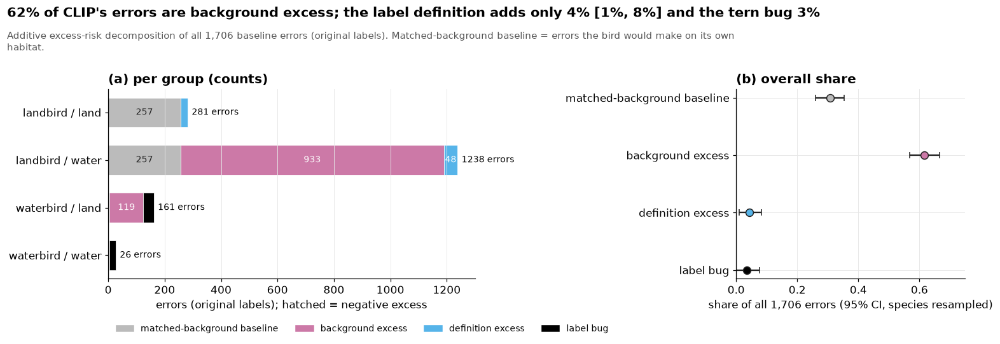

In [10]:
def excess_parts(d, hi=2):
    """Additive decomposition of the errors under the original labels (counts)."""
    out = {}
    bug = d[d.tern_bug]
    nb = d[~d.tern_bug]
    out["label bug"] = float((bug.pred != bug.label_original).sum())
    lbx, wbx = nb[nb.label == 0], nb[nb.label == 1]
    Nn = lbx[lbx.water_rating < hi]
    rN = {p: (Nn[Nn.place == p].err.mean()) for p in (0, 1)}
    rW = {p: (wbx[wbx.place == p].err.mean()) for p in (0, 1)}
    D = lbx[lbx.water_rating >= hi]
    parts = {g: dict.fromkeys(["label bug", "matched-background baseline", "background excess", "definition excess"], 0.0) for g in style.GROUPS}
    for p, g in [(0, "landbird / land"), (1, "landbird / water")]:
        n_all = (lbx.place == p).sum()
        parts[g]["matched-background baseline"] = n_all * rN[0]
        if p == 1:
            parts[g]["background excess"] = n_all * (rN[1] - rN[0])
        Dp = D[D.place == p]
        parts[g]["definition excess"] = Dp.err.sum() - len(Dp) * rN[p]
    for p, g in [(0, "waterbird / land"), (1, "waterbird / water")]:
        n_all = (wbx.place == p).sum()
        parts[g]["matched-background baseline"] = n_all * rW[1]
        if p == 0:
            parts[g]["background excess"] = n_all * (rW[0] - rW[1])
        parts[g]["label bug"] = float(((bug.place == p) & (bug.pred != bug.label_original)).sum())
    return pd.DataFrame(parts).T

PARTS = ["matched-background baseline", "background excess", "definition excess", "label bug"]
PART_COL = {"matched-background baseline": "#BBBBBB", "background excess": style.CUE_COLORS["background"],
            "definition excess": "#56B4E9", "label bug": "#000000"}
dec = excess_parts(df)
dec_tot = dec.sum()
n_err = int((df.pred != df.label_original).sum())
assert abs(dec_tot.sum() - n_err) < 1e-6, "the parts must add up to all errors"
display(dec.round(1))
from aivis.analysis import species_resamples
boot = np.array([(excess_parts(df.iloc[sel]).sum()[PARTS] / (df.iloc[sel].pred != df.iloc[sel].label_original).sum()).to_numpy()
                 for sel in species_resamples(df.species.to_numpy(), n_boot=1000)])
share = (dec_tot[PARTS] / n_err)
share_ci = pd.DataFrame({"share": share, "lo": np.quantile(boot, 0.025, axis=0), "hi": np.quantile(boot, 0.975, axis=0)}, index=PARTS)
display((100 * share_ci).round(1))
dec3 = excess_parts(df, hi=3).sum()
# what the first draft's rule-ordered decomposition (critique at check-in 5) called 'definition': every error of a
# non-bug landbird rated >= 2 that was called waterbird, regardless of the base rate
rule_def = int(((~df.tern_bug) & (df.label == 0) & (df.water_rating >= 2) & (df.pred == 1)).sum())

fig, (ax, bx) = plt.subplots(1, 2, figsize=(14, 4.2), gridspec_kw=dict(width_ratios=[1.6, 1]))
yy = np.arange(len(style.GROUPS))[::-1]
for gi, g in zip(yy, style.GROUPS):
    left = 0.0
    for c in PARTS:
        v = dec.loc[g, c]
        if v > 0:
            ax.barh(gi, v, left=left, color=PART_COL[c], height=0.62, edgecolor="white", lw=0.5)
            if v > 40:
                ax.text(left + v / 2, gi, f"{v:.0f}", ha="center", va="center", fontsize=9, color="white" if c != "matched-background baseline" else "#222")
            left += v
        elif v < 0:
            ax.barh(gi, v, left=0, color=PART_COL[c], height=0.62, hatch="///", edgecolor="white", lw=0.5)
    ax.text(left + 15, gi, f"{dec.loc[g].sum():.0f} errors", va="center", fontsize=9)
ax.axvline(0, color="#222", lw=0.8)
ax.set_yticks(yy, style.GROUPS); ax.set_xlabel("errors (original labels); hatched = negative excess")
ax.grid(axis="y", visible=False); ax.set_title("(a) per group (counts)")
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=PART_COL[c], label=c) for c in PARTS], ncol=4, loc="upper left", bbox_to_anchor=(0, -0.2), fontsize=9)
yb = np.arange(len(PARTS))[::-1]
bx.errorbar(share_ci.share, yb, xerr=[share_ci.share - share_ci.lo, share_ci.hi - share_ci.share], fmt="o", color="#222", capsize=3)
for y0, c in zip(yb, PARTS):
    bx.scatter(share_ci.loc[c, "share"], y0, color=PART_COL[c], s=60, zorder=3, edgecolor="#222")
bx.set_yticks(yb, PARTS); bx.set_xlim(0, 0.75); bx.axvline(0, color="#222", lw=0.8)
bx.set_xlabel(f"share of all {n_err:,} errors (95% CI, species resampled)"); bx.set_title("(b) overall share")
fig.tight_layout()
assert share_ci.loc["background excess", "lo"] > share_ci.loc["definition excess", "hi"], "claim: background excess > definition excess"
style.suptitle(fig, f"{pct(share['background excess'], 0)} of CLIP's errors are background excess; the label definition adds only "
               f"{pct(share['definition excess'], 0)} [{pct(share_ci.loc['definition excess', 'lo'], 0)}, {pct(share_ci.loc['definition excess', 'hi'], 0)}] "
               f"and the tern bug {pct(share['label bug'], 0)}",
               f"Additive excess-risk decomposition of all {n_err:,} baseline errors (original labels). Matched-background baseline = errors the bird would make on its own habitat.")
style.save(fig, "fig2b_error_decomposition"); plt.show()

In [11]:
from aivis.stats import spearman_ci
sp_lb = sp_stats[(sp_stats.label == 0) & (sp_stats.place_name == "water")]
rho = spearman_ci(sp_lb.rating, sp_lb.err)
kf = df[df.species.str.contains("Kingfisher") & (df.label == 0)]
assert rho[1] < 0 < rho[2], "claim: the species-level rank trend is weak (CI includes 0)"
md(f"""**Finding.** The label definition matters for a handful of species, not for "water-tied landbirds" in general.
The 5 aquatic landbird species (rating 3: the 4 American kingfishers and Louisiana Waterthrush) are wrong {pct(e3l.err)} [{pct(e3l.lo)}, {pct(e3l.hi)}] of the time on land backgrounds, where the background cannot be the cause, vs. {pct(e0l.err)} [{pct(e0l.lo)}, {pct(e0l.hi)}] for landbirds with no water tie (permutation p = {PV[('land', 3)]:.4f}). On water it is {pct(e3w.err)} vs. {pct(e0w.err)} (p = {PV[('water', 3)]:.4f}).
The 15 marsh and shore landbirds rated 2 (blackbirds, marsh sparrows, swallows, …) are *not* distinguishable from dry-land species (p = {PV[('land', 2)]:.2f} on land, {PV[('water', 2)]:.2f} on water); on land they are wrong only {pct(e2l.err)}. Across all landbird species the rank correlation between rating and error is weak (Spearman ρ = {rho[0]:.2f} [{rho[1]:.2f}, {rho[2]:.2f}]).
Counted as excess risk, the label definition explains {pct(share['definition excess'])} [{pct(share_ci.loc['definition excess', 'lo'])}, {pct(share_ci.loc['definition excess', 'hi'])}] of all {n_err:,} errors ({pct(dec3['definition excess'] / n_err)} if only rating 3 counts). The background excess explains {pct(share['background excess'])} [{pct(share_ci.loc['background excess', 'lo'])}, {pct(share_ci.loc['background excess', 'hi'])}], the tern bug {pct(share['label bug'])}, and {pct(share['matched-background baseline'])} are errors the bird would make on its own habitat anyway.
Our first, rule-ordered draft had put {rule_def} errors ({pct(rule_def / n_err)}) under "definition"; most of those were base-rate errors.""")

**Finding.** The label definition matters for a handful of species, not for "water-tied landbirds" in general.
The 5 aquatic landbird species (rating 3: the 4 American kingfishers and Louisiana Waterthrush) are wrong 49.4% [26.3%, 75.3%] of the time on land backgrounds, where the background cannot be the cause, vs. 11.8% [9.6%, 14.2%] for landbirds with no water tie (permutation p = 0.0001). On water it is 84.9% vs. 53.0% (p = 0.0017).
The 15 marsh and shore landbirds rated 2 (blackbirds, marsh sparrows, swallows, …) are *not* distinguishable from dry-land species (p = 0.40 on land, 0.08 on water); on land they are wrong only 9.0%. Across all landbird species the rank correlation between rating and error is weak (Spearman ρ = 0.14 [-0.02, 0.30]).
Counted as excess risk, the label definition explains 4.3% [1.0%, 8.2%] of all 1,706 errors (3.1% if only rating 3 counts). The background excess explains 61.7% [56.8%, 66.5%], the tern bug 3.4%, and 30.7% are errors the bird would make on its own habitat anyway.
Our first, rule-ordered draft had put 264 errors (15.5%) under "definition"; most of those were base-rate errors.

**Limitation.** The ratings come from language models. AI-rater agreement only shows consistency: the 4 raters share training data and could share the same mistakes. Correctness depends on the blind human check, which is still pending until we fill in `species_water_handcheck.csv`. The aquatic-landbird effect rests on only 5 species. The decomposition is additive and descriptive, not a causal model. For example, it does not separate *why* kingfishers look like waterbirds (plumage, posture, or the dataset's habitat definition; see the appearance cue in section 5).

## 3. Is the shortcut in the image or in the word?

**Question.** "Waterbird" might pull towards water scenes because of the *word* (in CLIP's training captions, "water bird" co-occurs with lakes and seas) or because of the *image* (the bird pixels are weak evidence compared to the scene). If the word is the problem, better wording should weaken the background effect. If the image is the problem, no wording will.

**Method.** Same 5,794 images, different text:
- **baseline:** "a photo of a landbird." / "a photo of a waterbird."
- **3 descriptive pairs:** "habitat words" (land bird / seabird or waterfowl), "example taxa" (songbird, woodpecker … / gull, duck, pelican …), "lives on" (lives on land / lives on water)
- **species routing:** zero-shot over the 200 species prompts ("a photo of a {species}, a type of bird."), then map the predicted species to land/water with the corrected labels. *Hard* = habitat of the arg-max species. *Soft* = log P(any water species) − log P(any land species), softmax over all 200.

Accuracy depends on where the threshold sits, and each prompt pair moves it. So we also report two **threshold-free** numbers, each a Mann-Whitney AUC on the water score s(x):
- **background AUC** = P(s on a water background > s on a land background | same class). 0.5 = the background has no effect; higher = stronger shortcut.
- **class AUC** = P(s of a waterbird > s of a landbird | same background). 1 = the two classes are fully separated.

CIs resample whole species (2,000 resamples), since images of one species are not independent. Differences to the baseline are paired, since the images are the same.

In [12]:
from aivis.analysis import threshold_free_diff
S = strategy_scores(L, species_label)
top_sp, hard_route = species_routing_hard(L, species_label)
preds = {name: (S[name] > 0).astype(int) for name, _, _ in PROMPT_PAIRS}
preds["species routing (hard)"] = hard_route
preds["species routing (soft)"] = (S["species routing"] > 0).astype(int)
STRATS = list(preds)
y = df["label"].to_numpy()
g_arr = df["group"].to_numpy()

rows = []
for name in STRATS:
    c = (preds[name] == y).astype(float)
    for g in ["overall"] + style.GROUPS:
        m_ = np.ones(len(c), bool) if g == "overall" else (g_arr == g)
        e = st.cluster_boot_mean(c[m_], df.species.to_numpy()[m_])
        rows.append(dict(strategy=name, group=g, n=int(m_.sum()), acc=e[0], lo=e[1], hi=e[2]))
strat_acc = pd.DataFrame(rows)
wide = strat_acc.pivot(index="strategy", columns="group", values="acc").loc[STRATS, ["overall"] + style.GROUPS]
wide["worst group"] = wide[style.GROUPS].min(axis=1)
display((100 * wide).round(1))

TF_NAMES = [n for n, _, _ in PROMPT_PAIRS] + ["species routing"]
tf = pd.DataFrame([dict(strategy=n, **threshold_free(S[n], df)) for n in TF_NAMES])
tfd = pd.DataFrame([dict(strategy=n, **threshold_free_diff(S[n], S["baseline"], df)) for n in TF_NAMES[1:]])
display(tf.round(3)); display(tfd.round(3))

species_top1 = (top_sp == df["species_id"].to_numpy())
print("species top-1 accuracy:", {g: pct(species_top1[g_arr == g].mean()) for g in style.GROUPS})

# Every qualitative claim in the text below is checked here.
desc = tfd[tfd.strategy.isin([n for n, _, _ in PROMPT_PAIRS[1:]])]
assert (desc.d_bg_lo > 0).all(), "claim: every rewording makes the background effect stronger"
rt = tfd.set_index("strategy").loc["species routing"]
assert rt.d_bg_lo < 0 < rt.d_bg_hi, "claim: species routing does not change the background effect"
assert rt.d_class_lo > 0, "claim: species routing separates the classes better"

group,overall,landbird / land,landbird / water,waterbird / land,waterbird / water,worst group
strategy,,,,,,
baseline,71.0,87.5,45.1,79.3,99.2,45.1
habitat words,81.3,99.3,75.1,30.9,86.1,30.9
example taxa,75.9,99.0,59.6,32.6,93.1,32.6
lives on,64.3,96.1,43.4,10.5,76.1,10.5
species routing (hard),84.8,97.0,74.2,68.3,95.3,68.3
species routing (soft),86.1,99.0,76.4,64.1,95.6,64.1


,strategy,bg_auc,bg_lo,bg_hi,class_auc,class_lo,class_hi
0,baseline,0.813,0.797,0.829,0.910,0.891,0.926
1,habitat words,0.870,0.857,0.884,0.900,0.883,0.916
2,example taxa,0.917,0.903,0.930,0.892,0.867,0.912
3,lives on,0.918,0.908,0.928,0.670,0.644,0.696
4,species routing,0.807,0.787,0.825,0.959,0.948,0.968


,strategy,d_bg,d_bg_lo,d_bg_hi,d_class,d_class_lo,d_class_hi
0,habitat words,0.057,0.045,0.069,-0.010,-0.026,0.005
1,example taxa,0.104,0.091,0.117,-0.018,-0.034,-0.002
2,lives on,0.105,0.092,0.117,-0.240,-0.265,-0.214
3,species routing,-0.006,-0.025,0.010,0.049,0.036,0.064


species top-1 accuracy: {'landbird / land': '28.1%', 'landbird / water': '20.1%', 'waterbird / land': '24.9%', 'waterbird / water': '25.2%'}


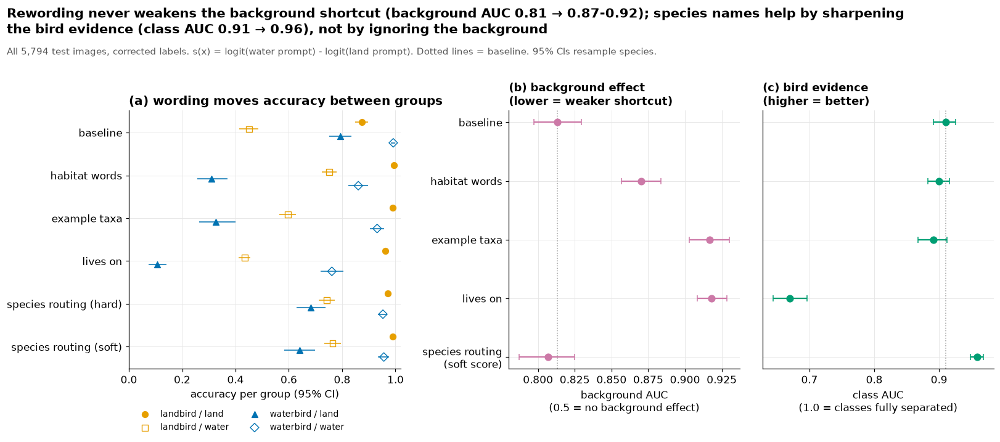

In [13]:
fig = plt.figure(figsize=(15, 5.6))
gs = fig.add_gridspec(1, 3, width_ratios=[1.3, 0.9, 0.9], wspace=0.5)
ax = fig.add_subplot(gs[0])
labels_order = STRATS[::-1]
for gi, g in enumerate(style.GROUPS):
    sub = strat_acc[strat_acc.group == g].set_index("strategy").loc[labels_order]
    yy = np.arange(len(labels_order)) + (1.5 - gi) * 0.16
    ax.errorbar(sub.acc, yy, xerr=[sub.acc - sub.lo, sub.hi - sub.acc], fmt="none", ecolor=style.GROUP_COLOR[g], lw=1)
    ax.scatter(sub.acc, yy, label=g, zorder=3, **style.group_scatter_kw(g, size=42, alpha=1))
ax.set_yticks(range(len(labels_order)), labels_order)
ax.set_xlabel("accuracy per group (95% CI)"); ax.set_xlim(0, 1.02)
ax.legend(loc="upper left", fontsize=9, ncol=2, bbox_to_anchor=(0, -0.13))
ax.set_title("(a) wording moves accuracy between groups")

tf_rows = TF_NAMES[::-1]
sub = tf.set_index("strategy").loc[tf_rows]
yy = np.arange(len(tf_rows))
inner = gs[1:].subgridspec(1, 2, wspace=0.1)
bx = fig.add_subplot(inner[0]); cx = fig.add_subplot(inner[1], sharey=bx)
bx.errorbar(sub.bg_auc, yy, xerr=[sub.bg_auc - sub.bg_lo, sub.bg_hi - sub.bg_auc], fmt="o", color=style.CUE_COLORS["background"], ms=7, capsize=3)
bx.axvline(sub.loc["baseline", "bg_auc"], color="#999", lw=1, ls=":")
bx.set_yticks(yy, [r if r != "species routing" else "species routing\n(soft score)" for r in tf_rows])
bx.set_xlabel("background AUC\n(0.5 = no background effect)")
bx.set_title("(b) background effect\n(lower = weaker shortcut)", fontsize=12)
cx.errorbar(sub.class_auc, yy, xerr=[sub.class_auc - sub.class_lo, sub.class_hi - sub.class_auc], fmt="o", color=style.CUE_COLORS["bird"], ms=7, capsize=3)
cx.axvline(sub.loc["baseline", "class_auc"], color="#999", lw=1, ls=":")
cx.tick_params(axis="y", labelleft=False, labelright=False, length=0)
cx.set_xlabel("class AUC\n(1.0 = classes fully separated)")
cx.set_title("(c) bird evidence\n(higher = better)", fontsize=12)
b0 = tf.set_index("strategy").loc["baseline"]; r0 = tf.set_index("strategy").loc["species routing"]
dsub = tf[tf.strategy.isin(desc.strategy)]
fig.subplots_adjust(left=0.13, right=0.98, bottom=0.2)
style.suptitle(fig, f"Rewording never weakens the background shortcut (background AUC {b0.bg_auc:.2f} → {dsub.bg_auc.min():.2f}-{dsub.bg_auc.max():.2f}); "
               f"species names help by sharpening the bird evidence (class AUC {b0.class_auc:.2f} → {r0.class_auc:.2f}), not by ignoring the background",
               "All 5,794 test images, corrected labels. s(x) = logit(water prompt) - logit(land prompt). Dotted lines = baseline. 95% CIs resample species.")
style.save(fig, "fig3_prompt_strategies"); plt.show()

,strategy,group,n,diff,lo,hi,fixed,broken
0,habitat words,waterbird / water,595,-13.1,-16.8,-9.6,2,80
1,habitat words,waterbird / land,599,-48.4,-54.1,-42.3,3,293
2,habitat words,landbird / land,2298,11.8,9.6,14.4,273,1
3,habitat words,landbird / water,2302,30.0,27.6,32.5,736,45
0,example taxa,waterbird / water,595,-6.1,-8.2,-4.0,0,36
1,example taxa,waterbird / land,599,-46.7,-52.6,-40.3,3,283
2,example taxa,landbird / land,2298,11.5,9.3,14.1,267,3
3,example taxa,landbird / water,2302,14.6,11.9,17.2,460,125
0,lives on,waterbird / water,595,-23.0,-27.3,-18.8,0,137
1,lives on,waterbird / land,599,-68.8,-73.1,-64.0,0,412


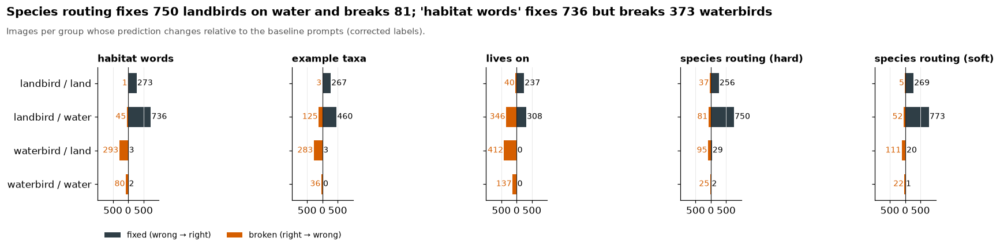

In [14]:
base_c = (preds["baseline"] == y).astype(int)
diffs = []
for name in STRATS[1:]:
    d = paired_group_diff((preds[name] == y).astype(int), base_c, g_arr, species=df.species.to_numpy())
    d.insert(0, "strategy", name)
    diffs.append(d)
diffs = pd.concat(diffs)
display(diffs.assign(diff=lambda d: (100 * d["diff"]).round(1), lo=lambda d: (100 * d.lo).round(1), hi=lambda d: (100 * d.hi).round(1)))

fig, axes = plt.subplots(1, len(STRATS) - 1, figsize=(15, 3.4), sharey=True, sharex=True)
for ax, name in zip(axes, STRATS[1:]):
    d = diffs[diffs.strategy == name].set_index("group").loc[style.GROUPS]
    yy = np.arange(len(style.GROUPS))[::-1]
    ax.barh(yy, d.fixed, color="#2F3E46", height=0.6, label="fixed (wrong → right)")
    ax.barh(yy, -d.broken, color=style.ERROR, height=0.6, label="broken (right → wrong)")
    for yv, f, b in zip(yy, d.fixed, d.broken):
        ax.text(f + 25, yv, str(f), va="center", fontsize=9)
        ax.text(-b - 25, yv, str(b), va="center", ha="right", fontsize=9, color=style.ERROR)
    ax.axvline(0, color="#222", lw=0.8); ax.set_title(name, fontsize=11)
    ax.grid(axis="y", visible=False)
axes[0].set_xlim(-1000, 1000); axes[0].set_xticks([-500, 0, 500], ["500", "0", "500"])
axes[0].set_yticks(np.arange(len(style.GROUPS))[::-1], style.GROUPS)
axes[0].legend(loc="upper left", bbox_to_anchor=(0, -0.18), ncol=2, fontsize=9)
fig.tight_layout()
hr = diffs[(diffs.strategy == "species routing (hard)") & (diffs.group == "landbird / water")].iloc[0]
hw = diffs[diffs.strategy == "habitat words"].set_index("group")
style.suptitle(fig, f"Species routing fixes {hr.fixed} landbirds on water and breaks {hr.broken}; 'habitat words' fixes {hw.loc['landbird / water', 'fixed']} "
               f"but breaks {hw.loc['waterbird / land', 'broken'] + hw.loc['waterbird / water', 'broken']} waterbirds",
               "Images per group whose prediction changes relative to the baseline prompts (corrected labels).")
style.save(fig, "fig3b_fixed_broken"); plt.show()

In [15]:
lbw = g_arr == "landbird / water"
wrong_route = lbw & (hard_route == 1)
picked = pd.Series([SPECIES[i] for i in top_sp[wrong_route]]).value_counts().head(10)
own_wrong = pd.Series(df.loc[wrong_route, "species"]).value_counts().head(8)
print("landbirds on water routed to a water species:", int(wrong_route.sum()), "of", int(lbw.sum()))
print("water species most often picked for them:\n", picked.to_string())
print("\nlandbird species most often routed to water:\n", own_wrong.to_string())
sp_acc_lbw = species_top1[lbw].mean(); sp_acc_lbl = species_top1[g_arr == "landbird / land"].mean()
md(f"""**Finding.** The prompt pairs reach very different accuracies, but mostly because each moves the threshold: one class gains and the other loses (panel a and the fixed/broken counts).
The threshold-free view shows the shortcut is **not in the word "waterbird"**. Every descriptive rewording makes the background effect *stronger*, not weaker: background AUC {b0.bg_auc:.3f} at baseline vs. {dsub.bg_auc.min():.3f} to {dsub.bg_auc.max():.3f} (paired difference CIs all above 0).
Routing through the 200 species names leaves the background effect where it was ({r0.bg_auc:.3f} vs. {b0.bg_auc:.3f}, paired difference {rt.d_bg:+.3f} [{rt.d_bg_lo:+.3f}, {rt.d_bg_hi:+.3f}]). What it improves is the bird evidence: class AUC {b0.class_auc:.3f} → {r0.class_auc:.3f} [{r0.class_lo:.3f}, {r0.class_hi:.3f}].
That is why routing lifts the worst group from {pct(wide.loc['baseline', 'worst group'])} to {pct(wide.loc['species routing (hard)', 'worst group'])}, even though the species itself is right only {pct(species_top1.mean())} of the time.
The background still leaks into the species decision: top-1 species accuracy for landbirds is {pct(sp_acc_lbl)} on land vs. {pct(sp_acc_lbw)} on water. {int(wrong_route.sum())} of {int(lbw.sum())} landbirds on water are still routed to a water species, most often {', '.join(picked.index[:3])}.""")

landbirds on water routed to a water species: 595 of 2302
water species most often picked for them:
 Brown_Pelican           67
Long_tailed_Jaeger      58
California_Gull         31
White_Pelican           30
Pelagic_Cormorant       30
Herring_Gull            28
Mallard                 28
Heermann_Gull           24
Pacific_Loon            21
Red_legged_Kittiwake    20

landbird species most often routed to water:
 species
Bank_Swallow              17
Belted_Kingfisher         12
Great_Grey_Shrike         12
Pileated_Woodpecker       12
Dark_eyed_Junco           11
Brown_Creeper             10
Marsh_Wren                10
Rose_breasted_Grosbeak     9


**Finding.** The prompt pairs reach very different accuracies, but mostly because each moves the threshold: one class gains and the other loses (panel a and the fixed/broken counts).
The threshold-free view shows the shortcut is **not in the word "waterbird"**. Every descriptive rewording makes the background effect *stronger*, not weaker: background AUC 0.813 at baseline vs. 0.870 to 0.918 (paired difference CIs all above 0).
Routing through the 200 species names leaves the background effect where it was (0.807 vs. 0.813, paired difference -0.006 [-0.025, +0.010]). What it improves is the bird evidence: class AUC 0.910 → 0.959 [0.948, 0.968].
That is why routing lifts the worst group from 45.1% to 68.3%, even though the species itself is right only 24.3% of the time.
The background still leaks into the species decision: top-1 species accuracy for landbirds is 28.1% on land vs. 20.1% on water. 595 of 2302 landbirds on water are still routed to a water species, most often Brown_Pelican, Long_tailed_Jaeger, California_Gull.

**Limitation.** We tried 3 hand-written descriptive pairs, which is not an exhaustive prompt search (e.g. no prompt ensembles). Species routing uses the corrected *dataset* labels of the species, so its errors include definition disagreements (section 2). The thresholds are not tuned; we report AUCs instead of calibrating each prompt on the validation split. The background AUC is a rank measure: it says *whether* the background moves the score, not by how many logits (section 4 measures the size).

## 4. Controlled cue-conflict experiment

**Question.** Sections 1-3 *observe* that the background matters. Here we *intervene*: we take the bird, the background and a written word apart and recombine them, holding everything else fixed. How much does each cue move CLIP's margin, and do the birds that are easily fooled by a background also get fooled by a word?

**Method, step 1: masks.** Every test image is segmented with `rembg` (U²-Net, a separate salient-object model; CPU, about 0.4 s per image, cached). We only use masks that pass a "clean" rule:
- foreground area between 2% and 60% of the canvas
- largest connected component ≥ 90% of the mask, at most 2 components larger than 1%
- at most 15% of the image border touched
- at most 35% soft (semi-transparent) pixels

The rule was fixed from the mask statistics and the contact sheets below, *before* any CLIP score of an edited image was computed.

In [16]:
from PIL import Image
from aivis import cue, experiment as ex
from aivis.data import canvases as make_canvases
CANV = make_canvases(ds)                                   # 5,794 x 224 x 224 x 3, cached
mask_path = config.CACHE_DIR / f"mask224_{len(ds)}.npy"
if not mask_path.exists():                                 # ~40 min on CPU, run once
    import subprocess
    subprocess.run([sys.executable, "-m", "aivis.segment_all"], check=True)
MASKS = np.load(mask_path, mmap_mode="r")
mt_path = config.CACHE_DIR / "mask_table.parquet"
if mt_path.exists():
    MT = pd.read_parquet(mt_path)
else:
    MT = ex.mask_table(MASKS); MT.to_parquet(mt_path)
df = pd.concat([df.drop(columns=[c for c in MT.columns if c in df.columns]), MT], axis=1)
print("clean masks:", int(MT.clean.sum()), "of", len(MT), f"({pct(MT.clean.mean())})")
display(df.groupby("group").agg(n=("clean", "size"), clean=("clean", "mean"), median_area=("mask_area", "median")).round(3))
reasons = pd.DataFrame({
    "area out of [2%, 60%]": ~MT.mask_area.between(0.02, 0.6),
    "fragmented": (MT.mask_largest_cc < 0.9) | (MT.mask_n_comp > 2),
    "touches border > 15%": MT.mask_border > 0.15,
    "too soft": MT.mask_soft > 0.35}).sum()
print("rejection reasons (not exclusive):\n", reasons.to_string())

clean masks: 5102 of 5794 (88.1%)


,n,clean,median_area
group,,,
landbird / land,2298,0.893,0.158
landbird / water,2302,0.873,0.177
waterbird / land,599,0.875,0.178
waterbird / water,595,0.867,0.184


rejection reasons (not exclusive):
 area out of [2%, 60%]     58
fragmented               254
touches border > 15%     239
too soft                 321


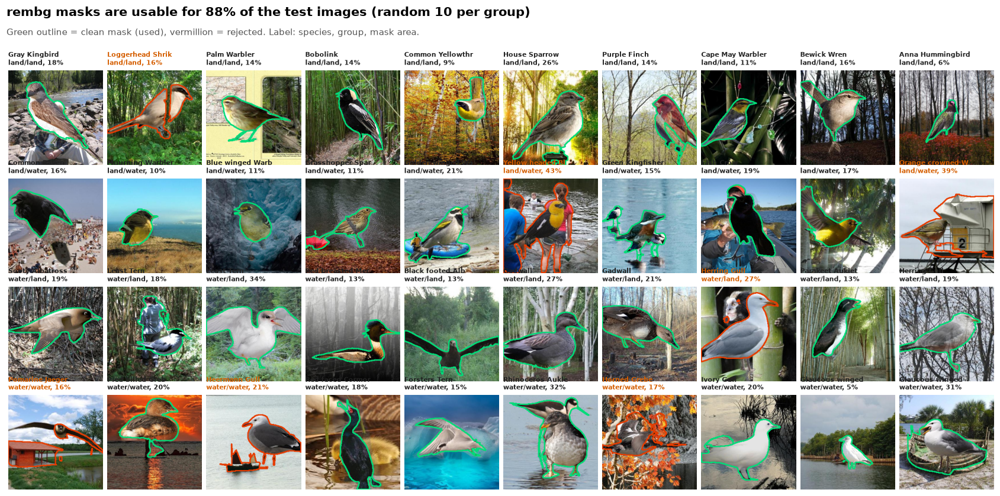

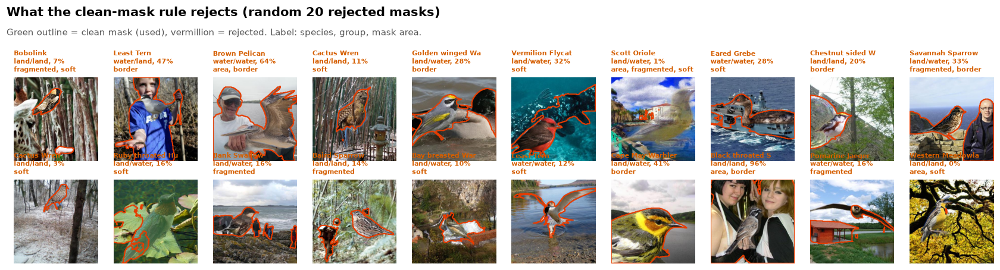

In [17]:
def outline(img_arr, m, color=(0, 220, 120)):
    """Thumbnail with the mask contour drawn on it."""
    import cv2
    a = np.asarray(img_arr).copy()
    cnts, _ = cv2.findContours((np.asarray(m) > 127).astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    cv2.drawContours(a, cnts, -1, color, 2)
    return a

def sheet(idxs, title, fname, ncol=10, extra=None):
    nrow = int(np.ceil(len(idxs) / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(ncol * 1.55, nrow * 1.75))
    for ax in axes.flat:
        ax.axis("off")
    for ax, i in zip(axes.flat, idxs):
        r = df.loc[i]
        ok = bool(r.clean)
        ax.imshow(outline(CANV[i], MASKS[i], (0, 220, 120) if ok else (230, 60, 0)))
        lab = f"{species_display(r.species)[:16]}\n{r.group.replace('bird / ', '/')}, {pct(r.mask_area, 0)}"
        if extra is not None:
            lab += "\n" + extra(r)
        ax.set_title(lab, fontsize=7, color="#222" if ok else style.ERROR)
    fig.tight_layout(h_pad=0.4, w_pad=0.2)
    style.suptitle(fig, title, "Green outline = clean mask (used), vermillion = rejected. Label: species, group, mask area.")
    style.save(fig, fname, svg=False, dpi=110); plt.show()

rng = np.random.default_rng(1)
rand_idx = np.concatenate([rng.choice(df.index[df.group == g], 10, replace=False) for g in style.GROUPS])
sheet(rand_idx, f"rembg masks are usable for {pct(MT.clean.mean(), 0)} of the test images (random 10 per group)", "fig4_qc_masks_random")
rej_idx = rng.choice(df.index[~df.clean], 20, replace=False)
def why(r):
    w = []
    if not 0.02 <= r.mask_area <= 0.6: w.append("area")
    if r.mask_largest_cc < 0.9 or r.mask_n_comp > 2: w.append("fragmented")
    if r.mask_border > 0.15: w.append("border")
    if r.mask_soft > 0.35: w.append("soft")
    return ", ".join(w)
sheet(rej_idx, "What the clean-mask rule rejects (random 20 rejected masks)", "fig4_qc_masks_rejected", extra=why)

**Method, step 2: background plates.** We need land and water scenes without a bird.

**First attempt, rejected:** following the plan, we took Waterbirds images whose rembg mask was tiny (0.2-3% of the canvas) and inpainted the bird away. The contact sheet showed that tiny masks are mostly *failed, partial* segmentations: in 4 of the 10 land plates the bird was still clearly visible after inpainting, and only 4 water images qualified at all. We kept that sheet as `outputs/fig4_qc_plates_rejected_attempt.png`.

**Used instead: bird-free crops.** For 120 random clean-mask images per background type we segment the *full-resolution* image with two independent models (U²-Net and IS-Net), take the union of both masks and dilate it by 3% of the shorter side. Then we cut out the largest square that avoids this region and resize it to 224 px. The scene keeps its real pixels, with no inpainting smudge, and a partial mask from one model doesn't leave the bird in the crop.

Candidates are ranked by crop size (relative to the shorter image side). Walking down that list, we keep a crop only if (1) no bird or bird part is visible, (2) the scene type is clearly recognisable (on water plates water must be a large part of the crop, not just a strip; land plates show vegetation) and (3) it is a colour photo. We stop at 10 per type. The AI did the visual check. At check-in 2 we rejected two water plates it had accepted (#66, #3294: too little water), tightened rule (2), and the walk continued down the list. Every rejection is listed with its reason. **No CLIP score is used for plate selection.** Plate images are excluded from the bird sample.

rejected while walking down the ranked list:


,idx,place,crop_rel_side,reason
0,1554,land,0.68,grayscale photo
1,361,water,0.85,a person fills part of the crop; mostly trees
2,66,water,0.67,"our decision at check-in 2: mostly trees, only..."
3,4839,water,0.64,palm trees and a roof; water barely visible
4,3294,water,0.62,"our decision at check-in 2: mostly mountain, l..."
5,253,water,0.61,"dune at dusk, no water visible"
6,5538,water,0.60,"hills, no water visible"
7,1269,water,0.60,"flat teal area, no recognisable scene"
8,3086,water,0.57,"snowy reeds, scene type unclear"
9,4583,water,0.56,"mostly bushes, water only at the edge (stricte..."


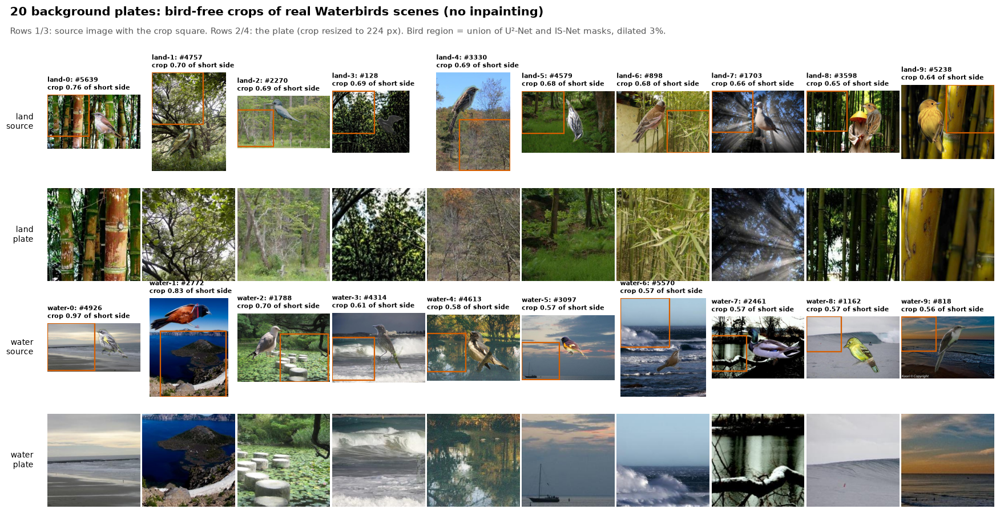

plate images: {0: [5639, 4757, 2270, 128, 3330, 4579, 898, 1703, 3598, 5238], 1: [4926, 2772, 1788, 4314, 4613, 3097, 5570, 2461, 1162, 818]}


In [18]:
PC = ex.plate_candidates(ds, df, MT, n_cand=120)
PLATE_PICK = {0: [5639, 4757, 2270, 128, 3330, 4579, 898, 1703, 3598, 5238],
              1: [4926, 2772, 1788, 4314, 4613, 3097, 5570, 2461, 1162, 818]}
PLATE_REJECT = {1554: "grayscale photo", 361: "a person fills part of the crop; mostly trees",
                66: "our decision at check-in 2: mostly trees, only a strip of river",
                4839: "palm trees and a roof; water barely visible",
                3294: "our decision at check-in 2: mostly mountain, little water",
                253: "dune at dusk, no water visible",
                5538: "hills, no water visible", 1269: "flat teal area, no recognisable scene",
                3086: "snowy reeds, scene type unclear",
                4583: "mostly bushes, water only at the edge (stricter rule after check-in 2)",
                2066: "trees only, no water visible"}
for place in (0, 1):
    ranked = PC[PC.place == place].sort_values("rel_side", ascending=False).idx.tolist()
    walked = [i for i in ranked[:ranked.index(PLATE_PICK[place][-1]) + 1]]
    assert [i for i in walked if i not in PLATE_REJECT] == PLATE_PICK[place], "picks must follow the ranked list"
PLATE_IDX = PLATE_PICK
PCi = PC.set_index("idx", drop=False)
PLATES = {pl: [ex.crop_plate(ds, PCi.loc[i]) for i in idxs] for pl, idxs in PLATE_IDX.items()}
print("rejected while walking down the ranked list:")
display(pd.DataFrame([dict(idx=i, place=["land", "water"][int(PCi.loc[i, "place"])], crop_rel_side=round(PCi.loc[i, "rel_side"], 2),
                           reason=r) for i, r in PLATE_REJECT.items()]))

from matplotlib.patches import Rectangle
fig, axes = plt.subplots(4, 10, figsize=(16, 7.6))
for row, place in enumerate((0, 1)):
    for k, i in enumerate(PLATE_IDX[place]):
        r = PCi.loc[i]
        a0, a1 = axes[2 * row, k], axes[2 * row + 1, k]
        a0.imshow(ds[int(i)]["image"]); a0.add_patch(Rectangle((r.x0, r.y0), r.side, r.side, fill=False, ec=style.ERROR, lw=1.5))
        a1.imshow(PLATES[place][k])
        a0.set_title(f"{['land', 'water'][place]}-{k}: #{i}\ncrop {r.rel_side:.2f} of short side", fontsize=7)
        a0.axis("off"); a1.axis("off")
for r_, t in enumerate(["land\nsource", "land\nplate", "water\nsource", "water\nplate"]):
    axes[r_, 0].text(-0.15, 0.5, t, transform=axes[r_, 0].transAxes, ha="right", va="center", fontsize=9)
fig.tight_layout(h_pad=0.3, w_pad=0.2)
style.suptitle(fig, "20 background plates: bird-free crops of real Waterbirds scenes (no inpainting)",
               "Rows 1/3: source image with the crop square. Rows 2/4: the plate (crop resized to 224 px). Bird region = union of U²-Net and IS-Net masks, dilated 3%.")
style.save(fig, "fig4_qc_plates", svg=False, dpi=110); plt.show()
print("plate images:", PLATE_IDX)

**Method, step 3: sample and conditions.** Per class × background group we draw birds with clean masks, round-robin over species so that as many species as possible are covered (plate images excluded). Each bird gets these conditions, all on the 224 × 224 canvas that CLIP sees:

| condition | what changes | levels |
|---|---|---|
| original | nothing (reference) | 1 |
| bird only | background → neutral gray, bird in place | 1 |
| background only | bird inpainted away | 1 |
| pasted on gray / matching plate / conflicting plate | bird cut out, centered, scaled | 8 scales (1.0 = longer side 80% of canvas, down to 0.15) |
| text on original | "landbird", "waterbird", neutral "triangle" in a white box, in the band away from the bird | 8 cap heights (2%-12% of canvas) |
| extra words on original | ocean, lake, beach, forest, tree, grass, duck, seagull, sparrow, nonsense "xkqzvrtb", misspelled "watrbird" | 2 sizes (6%, 12%) |
| words on the gray base | all 14 words on the bird pasted at scale 0.5 on gray | 1 size (8%) |

In the first run the matching / conflicting plate was drawn at random per bird from the 10 plates of each type. The gray-base series is the control for "the bird gets smaller": the background effect at a given scale is measured against the same bird on gray at the same scale.

**Follow-up run (after the critique at check-in 5).** With one random plate per bird, about 120 birds shared each plate, and our first CIs ignored that. Now every bird is also pasted on **all 20 plates at all 8 scales**, so plates become a crossed factor and are resampled in the CIs. We also added a **same-base word grid** for a fair word-vs-scene comparison: the bird on gray at scales 1.0 / 0.5 / 0.15, with "waterbird", "landbird", "triangle", a blank white box and two random strings, each at 4 / 8 / 12% height.

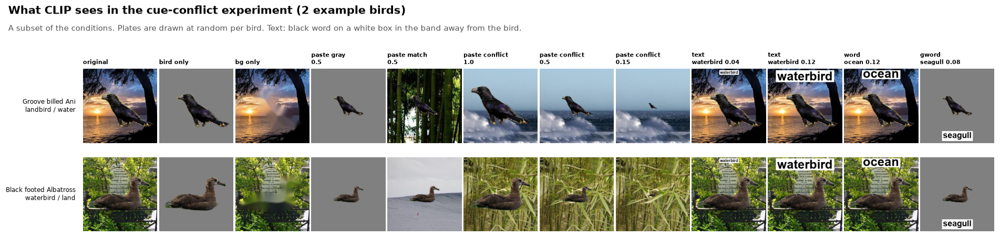

In [19]:
ex_birds = [df.index[(df.group == "landbird / water") & df.clean][3], df.index[(df.group == "waterbird / land") & df.clean][5]]
show = [("original", None), ("bird_only", None), ("bg_only", None), ("paste_gray", 0.5), ("paste_match", 0.5),
        ("paste_conflict", 1.0), ("paste_conflict", 0.5), ("paste_conflict", 0.15),
        ("text", ("waterbird", 0.04)), ("text", ("waterbird", 0.12)), ("word", ("ocean", 0.12)), ("gword", ("seagull", 0.08))]
fig, axes = plt.subplots(len(ex_birds), len(show), figsize=(len(show) * 1.45, len(ex_birds) * 1.85))
for r, i in enumerate(ex_birds):
    conds = list(ex.conditions(i, df.loc[i], CANV[i], MASKS[i], PLATES, np.random.default_rng(0)))
    for c, (name, arg) in enumerate(show):
        for rec, im in conds:
            if rec["cond"] != name:
                continue
            if name.startswith("paste") and rec["scale"] != arg:
                continue
            if name in ("text", "word", "gword") and (rec["word"], rec["size"]) != arg:
                continue
            axes[r, c].imshow(im); break
        axes[r, c].axis("off")
        lab = name.replace("_", " ") + ("" if arg is None else f"\n{arg if not isinstance(arg, tuple) else ' '.join(map(str, arg))}")
        if r == 0:
            axes[r, c].set_title(lab, fontsize=7.5)
    axes[r, 0].text(-0.1, 0.5, f"{species_display(df.species[i])}\n{df.group[i]}", transform=axes[r, 0].transAxes,
                    ha="right", va="center", fontsize=8)
fig.tight_layout(w_pad=0.2)
style.suptitle(fig, "What CLIP sees in the cue-conflict experiment (2 example birds)",
               "A subset of the conditions. Plates are drawn at random per bird. Text: black word on a white box in the band away from the bird.")
style.save(fig, "fig4_qc_conditions", svg=False, dpi=130); plt.show()

In [20]:
PER_GROUP = 300          # planned 150; doubled because scoring is fast (see runtime below)
exclude = PLATE_IDX[0] + PLATE_IDX[1]
SAMPLE = ex.select_sample(df, MT, PER_GROUP, exclude=exclude)
print("birds:", len(SAMPLE), "| per group:", df.loc[SAMPLE].group.value_counts().to_dict(),
      "| species:", df.loc[SAMPLE].species.nunique())
t0 = time.time()
CUE, THUMBS = ex.run(df, SAMPLE, CANV, MASKS, PLATES, scorer, bank[:2], name=f"v1_{PER_GROUP}")
assert set(CUE.idx.unique()) == set(SAMPLE.tolist()), "cached v1 scores belong to a different sample"
print(f"run 1: {len(CUE):,} edited images ({len(CUE) // len(SAMPLE)} per bird) in {time.time() - t0:.0f} s (0 s = cached)")
# Follow-up after the critique (check-in 5): every bird on ALL 20 plates, and a same-base word grid.
t0 = time.time()
CUE2 = ex.run_v2(SAMPLE, CANV, MASKS, PLATES, PLATE_IDX, scorer, bank[:2], name=f"v2_{PER_GROUP}")
CUE2 = CUE2.merge(df[["idx", "label", "species", "group"]], on="idx", how="left")
CUE2["margin"] = np.where(CUE2.label == 1, CUE2.s, -CUE2.s)
print(f"run 2: {len(CUE2):,} edited images ({len(CUE2) // len(SAMPLE)} per bird) in {time.time() - t0:.0f} s (0 s = cached)")
ref = df.set_index("idx").loc[SAMPLE, "s"].to_numpy()
orig = CUE[CUE.cond == "original"].set_index("idx").loc[SAMPLE, "s"].to_numpy()
print(f"canvas vs. processor input: max |s| difference {np.abs(orig - ref).max():.3f}, "
      f"prediction agreement {pct(((orig > 0) == (ref > 0)).mean())}")
SPC = df.set_index("idx").species     # species of each bird, for cluster bootstraps

def plate_matrix(scale, role, value="margin"):
    """birds x 10 plates matrix for one scale; role = 'conflicting' / 'matching' / 'water' / 'land'."""
    d = CUE2[(CUE2.cond == "plate") & (CUE2.scale == scale)]
    if role in ("conflicting", "matching"):
        same = d.plate_place == d.label
        d = d[same] if role == "matching" else d[~same]
    else:
        d = d[d.plate_place == (1 if role == "water" else 0)]
    return d.pivot_table(index="idx", columns="plate_k", values=value)

birds: 1200 | per group: {'waterbird / water': 300, 'waterbird / land': 300, 'landbird / water': 300, 'landbird / land': 300} | species: 200


run 1: 104,400 edited images (87 per bird) in 1 s (0 s = cached)
run 2: 256,800 edited images (214 per bird) in 0 s (0 s = cached)
canvas vs. processor input: max |s| difference 0.739, prediction agreement 98.5%


cues disagree for 570 of 1200 birds; the original prediction follows the bird in 65.4% [60.7, 70.0] (species resampled)


,share following the background,birds with conflicting cues
group,,
landbird / land,0.367,60
landbird / water,0.486,253
waterbird / land,0.152,231
waterbird / water,0.654,26


mean |water score|: bird only 3.03, background only 1.97
s(original) = 0.67 [0.65, 0.69] * s(bird) + 0.65 [0.62, 0.69] * s(background) + 0.31 [0.22, 0.41];  R^2 = 0.83


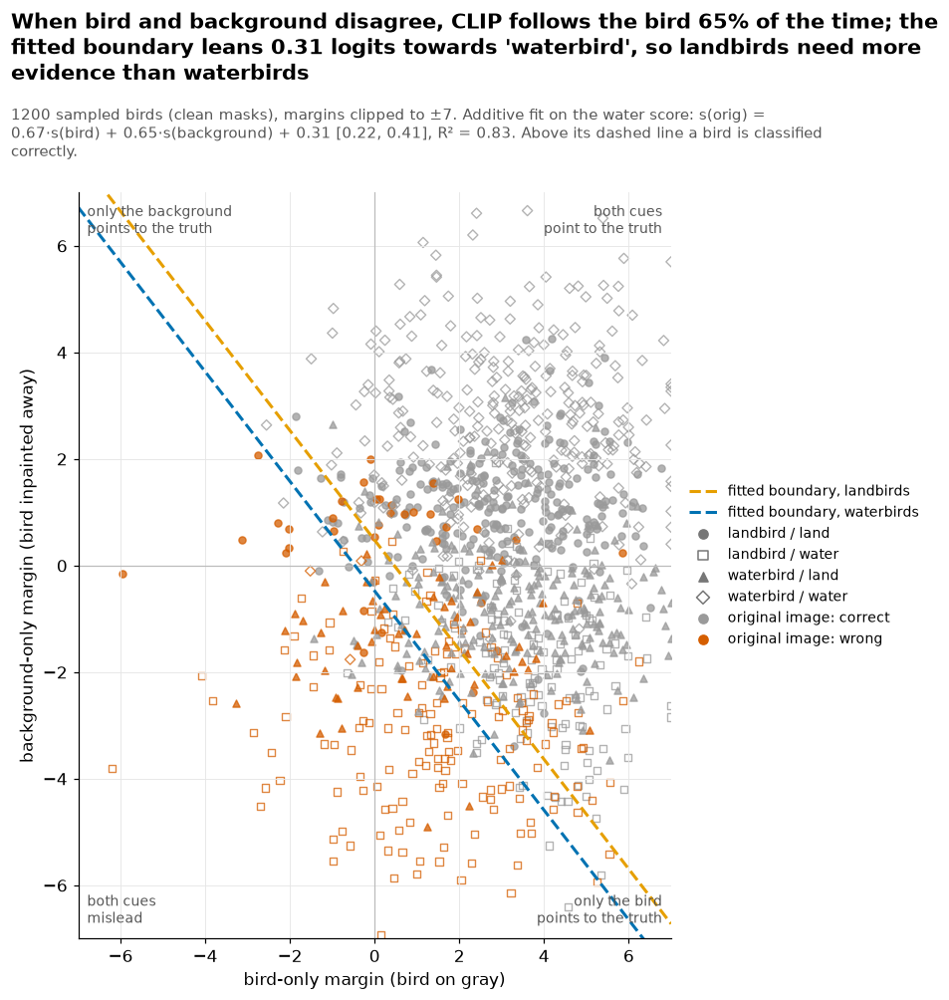

In [21]:
W = CUE.pivot_table(index="idx", columns="cond", values="margin", aggfunc="first")[["original", "bird_only", "bg_only"]]
W = W.join(df.set_index("idx")[["label", "place", "group", "species", "water_rating", "mask_area"]])
W["orig_correct"] = W.original > 0
conflict = np.sign(W.bird_only) != np.sign(W.bg_only)
follows_bg = np.sign(W.original) == np.sign(W.bg_only)
# additive cue model on the water score: s(original) ~ a * s(bird only) + b * s(background only) + c
Sv = CUE.pivot_table(index="idx", columns="cond", values="s", aggfunc="first").loc[W.index]
A_ = np.column_stack([Sv.bird_only, Sv.bg_only, np.ones(len(Sv))])
coef = np.linalg.lstsq(A_, Sv.original, rcond=None)[0]
r2 = 1 - np.var(Sv.original - A_ @ coef) / np.var(Sv.original)
from aivis.analysis import species_resamples
pos_ = {i: k for k, i in enumerate(W.index)}
bc = np.array([np.linalg.lstsq(A_[sel], Sv.original.to_numpy()[sel], rcond=None)[0]
               for sel in species_resamples(W.species.to_numpy(), n_boot=1000)])
bc = np.quantile(bc, [0.025, 0.975], axis=0)
fbird = st.cluster_boot_mean((1 - follows_bg[conflict]).to_numpy(float), W.species[conflict])
fb_grp = pd.DataFrame({"conflict": conflict, "fbg": follows_bg, "group": W.group}).query("conflict").groupby("group").fbg.agg(["mean", "size"])
print(f"cues disagree for {int(conflict.sum())} of {len(W)} birds; the original prediction follows the bird in {st.fmt_ci(*fbird, pct=True)} (species resampled)")
display(fb_grp.rename(columns={"mean": "share following the background", "size": "birds with conflicting cues"}).round(3))
print(f"mean |water score|: bird only {Sv.bird_only.abs().mean():.2f}, background only {Sv.bg_only.abs().mean():.2f}")
print(f"s(original) = {coef[0]:.2f} [{bc[0,0]:.2f}, {bc[1,0]:.2f}] * s(bird) + {coef[1]:.2f} [{bc[0,1]:.2f}, {bc[1,1]:.2f}] * s(background) "
      f"+ {coef[2]:.2f} [{bc[0,2]:.2f}, {bc[1,2]:.2f}];  R^2 = {r2:.2f}")

fig, ax = plt.subplots(figsize=(8.6, 7.6))
lim = 7
for g in style.GROUPS:
    d = W[W.group == g]
    for ok, col in [(True, style.CORRECT), (False, style.ERROR)]:
        dd = d[d.orig_correct == ok]
        filled = style.GROUP_FILLED[g]
        ax.scatter(dd.bird_only.clip(-lim, lim), dd.bg_only.clip(-lim, lim), marker=style.GROUP_MARKER[g], s=22,
                   facecolors=col if filled else "none", edgecolors=col, lw=0.9, alpha=0.75)
ax.axhline(0, color="#BBBBBB", lw=0.8); ax.axvline(0, color="#BBBBBB", lw=0.8)
# fitted decision lines in margin space: correct above the line of the bird's class
xs_ = np.linspace(-lim, lim, 50)
a_, b_, c_ = coef
ax.plot(xs_, (c_ - a_ * xs_) / b_, color=style.LAND, lw=2, ls="--", label="fitted boundary, landbirds")
ax.plot(xs_, -(c_ + a_ * xs_) / b_, color=style.WATER, lw=2, ls="--", label="fitted boundary, waterbirds")
for (x_, y_, t) in [(lim * 0.97, lim * 0.97, "both cues\npoint to the truth"), (-lim * 0.97, lim * 0.97, "only the background\npoints to the truth"),
                    (lim * 0.97, -lim * 0.97, "only the bird\npoints to the truth"), (-lim * 0.97, -lim * 0.97, "both cues\nmislead")]:
    ax.text(x_, y_, t, ha="right" if x_ > 0 else "left", va="top" if y_ > 0 else "bottom", fontsize=9, color="#555")
ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim)
ax.set_xlabel("bird-only margin (bird on gray)"); ax.set_ylabel("background-only margin (bird inpainted away)")
for g in style.GROUPS:
    ax.scatter([], [], marker=style.GROUP_MARKER[g], facecolors="#777" if style.GROUP_FILLED[g] else "none", edgecolors="#777", label=g)
ax.scatter([], [], color=style.CORRECT, label="original image: correct"); ax.scatter([], [], color=style.ERROR, label="original image: wrong")
ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5), fontsize=9)
fig.tight_layout()
assert fbird[1] > 0.5 and bc[0, 2] > 0, "claims: the bird wins most conflicts; the fitted intercept leans 'waterbird'"
style.suptitle(fig, f"When bird and background disagree, CLIP follows the bird {pct(fbird[0], 0)} of the time; the fitted boundary "
               f"leans {coef[2]:.2f} logits towards 'waterbird', so landbirds need more evidence than waterbirds",
               f"{len(W)} sampled birds (clean masks), margins clipped to ±{lim}. Additive fit on the water score: s(orig) = {coef[0]:.2f}·s(bird) + "
               f"{coef[1]:.2f}·s(background) + {coef[2]:.2f} [{bc[0,2]:.2f}, {bc[1,2]:.2f}], R² = {r2:.2f}. Above its dashed line a bird is classified correctly.", wrap=80)
style.save(fig, "fig4a_cue_quadrant"); plt.show()

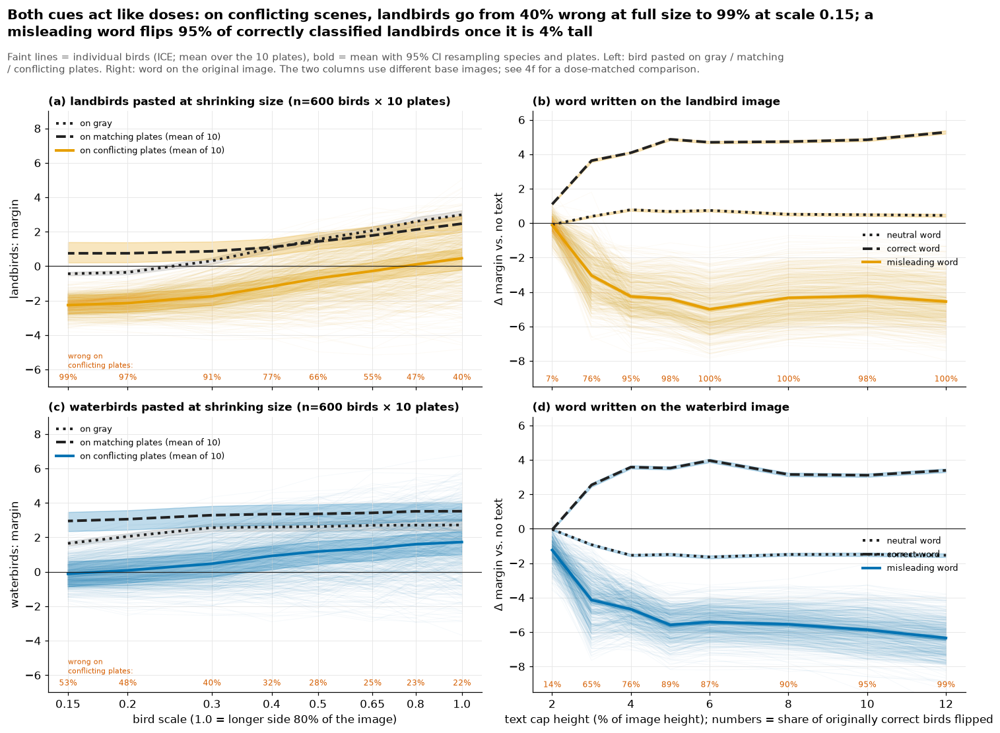

In [22]:
P = CUE[CUE.cond == "paste_gray"][["idx", "scale", "margin"]].rename(columns={"margin": "paste_gray"})
P = P.merge(df[["idx", "label", "group", "species"]], on="idx")
T = CUE[CUE.cond == "text"].copy()
T = T.merge(CUE[CUE.cond == "original"][["idx", "margin"]].rename(columns={"margin": "m0"}), on="idx")
T["dm"] = T.margin - T.m0
T["role"] = np.select([T.word == ex.NEUTRAL_WORD, ((T.word == "waterbird") & (T.label == 0)) | ((T.word == "landbird") & (T.label == 1))],
                      ["neutral word", "misleading word"], "correct word")
NB = 500   # bootstrap resamples for the per-scale bands (two-way: species of birds x plates)
band = {}
for lab in (0, 1):
    for role in ("conflicting", "matching"):
        for s_ in ex.SCALES:
            M = plate_matrix(s_, role)
            M = M.loc[M.index.isin(df.index[df.label == lab])]
            e = st.two_way_boot_mean(M.to_numpy(), SPC.loc[M.index].to_numpy(), n_boot=NB)
            wv = st.two_way_boot_mean((M.to_numpy() < 0).astype(float), SPC.loc[M.index].to_numpy(), n_boot=NB)
            band[(lab, role, s_)] = (e, wv, M.mean(axis=1))

fig, axes = plt.subplots(2, 2, figsize=(13.5, 9), sharex="col")
for r, lab in enumerate((0, 1)):
    col = style.CLASS_COLORS[lab]
    ax = axes[r, 0]
    ice = pd.concat({s_: band[(lab, "conflicting", s_)][2] for s_ in ex.SCALES}, axis=1)
    for i in ice.index:
        ax.plot(ex.SCALES, ice.loc[i].to_numpy(), color=col, alpha=0.035, lw=0.7)
    d = P[P.label == lab]
    mm = d.groupby("scale").paste_gray.mean()
    gci = [st.cluster_boot_mean(d[d.scale == s_].paste_gray, d[d.scale == s_].species, n_boot=NB) for s_ in mm.index]
    ax.plot(mm.index, mm, ls=":", color="#222", lw=2.6, label="on gray")
    ax.fill_between(mm.index, [g_[1] for g_ in gci], [g_[2] for g_ in gci], color="#999", alpha=0.25)
    for role, ls, c_line in [("matching", "--", "#222"), ("conflicting", "-", col)]:
        est = [band[(lab, role, s_)][0] for s_ in ex.SCALES]
        ax.plot(ex.SCALES, [e[0] for e in est], ls=ls, color=c_line, lw=2.6, label=f"on {role} plates (mean of 10)")
        ax.fill_between(ex.SCALES, [e[1] for e in est], [e[2] for e in est], color=col, alpha=0.25)
    ax.axhline(0, color="#222", lw=0.8); ax.set_xscale("log"); ax.set_xticks(ex.SCALES, [str(s) for s in ex.SCALES])
    ax.minorticks_off(); ax.set_ylim(-7, 9)
    for s_ in ex.SCALES:
        ax.text(s_, -6.6, pct(band[(lab, "conflicting", s_)][1][0], 0), ha="center", fontsize=8, color=style.ERROR)
    ax.text(ex.SCALES[-1], -5.9, "wrong on\nconflicting plates:", fontsize=7.5, color=style.ERROR, ha="left")
    ax.set_ylabel(f"{CLASS_NAMES[lab]}s: margin")
    ax.set_title(f"({'a' if r == 0 else 'c'}) {CLASS_NAMES[lab]}s pasted at shrinking size (n={ice.shape[0]} birds × 10 plates)", fontsize=11)
    if r == 1: ax.set_xlabel("bird scale (1.0 = longer side 80% of the image)")
    ax.legend(loc="upper left", fontsize=8.5)
    bx = axes[r, 1]
    d = T[T.label == lab]
    for i, dd in d[d.role == "misleading word"].groupby("idx"):
        bx.plot(dd["size"] * 100, dd.dm, color=col, alpha=0.035, lw=0.7)
    for role, ls in [("neutral word", ":"), ("correct word", "--"), ("misleading word", "-")]:
        dr = d[d.role == role]
        mm = dr.groupby("size").dm.mean()
        ci_ = [st.cluster_boot_mean(dr[dr["size"] == z].dm, dr[dr["size"] == z].species, n_boot=NB) for z in mm.index]
        bx.plot(mm.index * 100, mm, ls=ls, color=col if role == "misleading word" else "#222", lw=2.6, label=role)
        bx.fill_between(mm.index * 100, [c[1] for c in ci_], [c[2] for c in ci_], color=col, alpha=0.25)
    bx.axhline(0, color="#222", lw=0.8); bx.set_ylim(-9.5, 6.5)
    ok0 = d.m0 > 0
    flip = d[(d.role == "misleading word") & ok0].assign(w=lambda v: v.margin < 0).groupby("size").w.mean()
    for s_, v in flip.items():
        bx.text(s_ * 100, -9.2, pct(v, 0), ha="center", fontsize=8, color=style.ERROR)
    bx.set_ylabel("Δ margin vs. no text")
    bx.set_title(f"({'b' if r == 0 else 'd'}) word written on the {CLASS_NAMES[lab]} image", fontsize=11)
    if r == 1: bx.set_xlabel("text cap height (% of image height); numbers = share of originally correct birds flipped")
    bx.legend(loc="center right", fontsize=8.5)
fig.tight_layout()
w_conf = {lab: (band[(lab, "conflicting", 1.0)][1], band[(lab, "conflicting", min(ex.SCALES))][1]) for lab in (0, 1)}
flip_c = {lab: T[(T.label == lab) & (T.role == "misleading word") & (T.m0 > 0)].assign(w=lambda v: v.margin < 0).groupby("size").w.mean() for lab in (0, 1)}
box4 = cue.text_box_area("waterbird", 0.04)
style.suptitle(fig, f"Both cues act like doses: on conflicting scenes, landbirds go from {pct(w_conf[0][0][0], 0)} wrong at full size to "
               f"{pct(w_conf[0][1][0], 0)} at scale {min(ex.SCALES)}; a misleading word flips {pct(flip_c[0][0.04], 0)} of correctly classified "
               f"landbirds once it is 4% tall",
               "Faint lines = individual birds (ICE; mean over the 10 plates), bold = mean with 95% CI resampling species and plates. Left: bird pasted on gray / "
               "matching / conflicting plates. Right: word on the original image. The two columns use different base images; see 4f for a dose-matched comparison.")
style.save(fig, "fig4b_dose_response"); plt.show()

**One shared weakness or two separate shortcuts?** Two questions, two measures:
- **Are the same birds fooled?** Per bird, the *share of conditions that end wrong*: on conflicting plates (8 scales × 10 plates) and with the misleading word on the original image (8 sizes).
- **Does each cue move the same birds by the same amount?** Per bird, the *cue-specific shift on one shared base* (bird pasted at scale 0.5 on gray). Background shift = mean margin on the 10 conflicting plates − margin on gray. Text shift = margin with the misleading word (8% height) − mean margin with the 4 neutral controls ("triangle", a blank box, 2 random strings).

Our first draft used only margin-loss measures and concluded "two separate shortcuts". The critique at check-in 5 showed that this removes exactly the shared factor (weak bird evidence) the question is about. Both measures are shown now; CIs resample species.

,rho,lo,hi,n
landbird: fooled,0.394,0.318,0.464,600.0
landbird: shift,0.190,0.093,0.281,600.0
landbird: bg_fooled~orig,-0.522,-0.582,-0.449,600.0
landbird: text_fooled~orig,-0.846,-0.866,-0.821,600.0
waterbird: fooled,0.316,0.226,0.405,600.0
waterbird: shift,0.333,0.249,0.405,600.0
waterbird: bg_fooled~orig,-0.364,-0.456,-0.273,600.0
waterbird: text_fooled~orig,-0.863,-0.884,-0.837,600.0


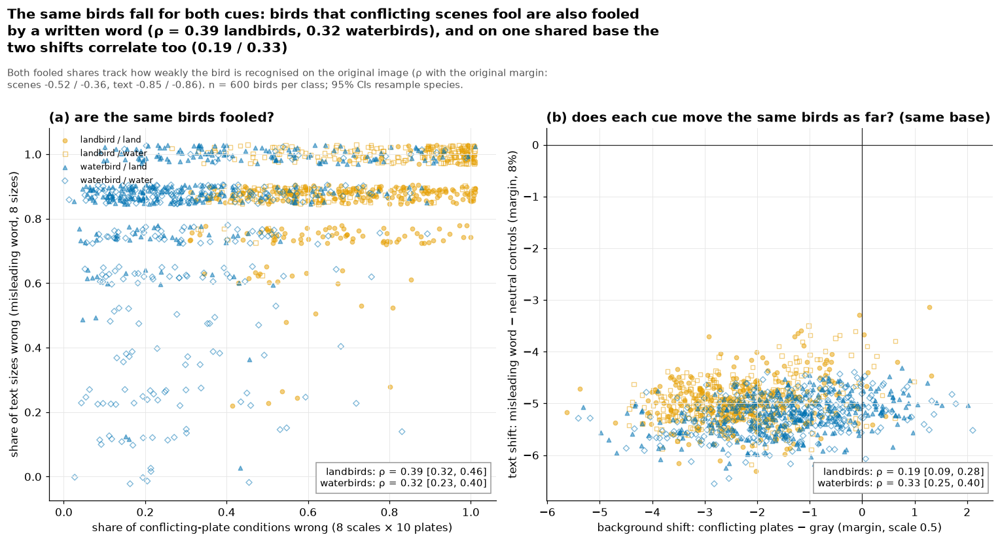

In [23]:
ctrl_words = ["triangle", "[blank box]", "qorvtenl", "zbxkwtpm"]
G2 = CUE2[CUE2.cond == "gword2"]
def gword2(scale, size):
    d = G2[(G2.scale == scale) & (G2["size"] == size)]
    mis = d[((d.word == "waterbird") & (d.label == 0)) | ((d.word == "landbird") & (d.label == 1))].set_index("idx").margin
    ctl = d[d.word.isin(ctrl_words)].groupby("idx").margin.mean()
    return mis, ctl
gray_m = CUE[CUE.cond == "paste_gray"].pivot_table(index="idx", columns="scale", values="margin")

R = pd.DataFrame(index=W.index)
R["bg_fooled"] = pd.concat([(plate_matrix(s_, "conflicting") < 0).mean(axis=1) for s_ in ex.SCALES], axis=1).mean(axis=1)
R["text_fooled"] = T[T.role == "misleading word"].assign(w=lambda v: v.margin < 0).groupby("idx").w.mean()
mis05, ctl05 = gword2(0.5, 0.08)
R["bg_shift"] = plate_matrix(0.5, "conflicting").mean(axis=1) - gray_m[0.5]
R["text_shift"] = mis05 - ctl05
R = R.join(W[["bird_only", "original", "label", "group", "species"]])
RHO = {}
for lab in (0, 1):
    d = R[R.label == lab]
    RHO[(lab, "fooled")] = spearman_ci(d.bg_fooled, d.text_fooled, clusters=d.species)
    RHO[(lab, "shift")] = spearman_ci(d.bg_shift, d.text_shift, clusters=d.species)
    RHO[(lab, "bg_fooled~orig")] = spearman_ci(d.bg_fooled, d.original, clusters=d.species)
    RHO[(lab, "text_fooled~orig")] = spearman_ci(d.text_fooled, d.original, clusters=d.species)
display(pd.DataFrame({f"{CLASS_NAMES[k[0]]}: {k[1]}": dict(rho=v[0], lo=v[1], hi=v[2], n=v[3]) for k, v in RHO.items()}).T.round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 6.2))
jit = np.random.default_rng(0)
for lab in (0, 1):
    d = R[R.label == lab]
    for g in [x for x in style.GROUPS if x.startswith(CLASS_NAMES[lab])]:
        dd = d[d.group == g]
        axes[0].scatter(dd.bg_fooled + jit.uniform(-0.012, 0.012, len(dd)), dd.text_fooled + jit.uniform(-0.03, 0.03, len(dd)),
                        **style.group_scatter_kw(g, size=18, alpha=0.5), label=g)
        axes[1].scatter(dd.bg_shift, dd.text_shift, **style.group_scatter_kw(g, size=18, alpha=0.5))
axes[0].set_xlabel("share of conflicting-plate conditions wrong (8 scales × 10 plates)")
axes[0].set_ylabel("share of text sizes wrong (misleading word, 8 sizes)")
axes[0].set_title("(a) are the same birds fooled?")
axes[1].set_xlabel("background shift: conflicting plates − gray (margin, scale 0.5)")
axes[1].set_ylabel("text shift: misleading word − neutral controls (margin, 8%)")
axes[1].set_title("(b) does each cue move the same birds as far? (same base)")
axes[1].axhline(0, color="#222", lw=0.8); axes[1].axvline(0, color="#222", lw=0.8)
for ax, key in [(axes[0], "fooled"), (axes[1], "shift")]:
    ax.text(0.98, 0.03, "\n".join(f"{CLASS_NAMES[l]}s: ρ = {RHO[(l, key)][0]:.2f} [{RHO[(l, key)][1]:.2f}, {RHO[(l, key)][2]:.2f}]" for l in (0, 1)),
            transform=ax.transAxes, ha="right", va="bottom", fontsize=9.5, bbox=dict(fc="white", ec="#999"))
axes[0].legend(loc="upper left", fontsize=8.5)
fig.tight_layout()
assert all(RHO[(l, "fooled")][1] > 0 and RHO[(l, "shift")][1] > 0 for l in (0, 1)), "claim: both measures correlate positively in both classes"
style.suptitle(fig, f"The same birds fall for both cues: birds that conflicting scenes fool are also fooled by a written word "
               f"(ρ = {RHO[(0, 'fooled')][0]:.2f} landbirds, {RHO[(1, 'fooled')][0]:.2f} waterbirds), and on one shared base the two shifts correlate too "
               f"({RHO[(0, 'shift')][0]:.2f} / {RHO[(1, 'shift')][0]:.2f})",
               f"Both fooled shares track how weakly the bird is recognised on the original image (ρ with the original margin: scenes "
               f"{RHO[(0, 'bg_fooled~orig')][0]:.2f} / {RHO[(1, 'bg_fooled~orig')][0]:.2f}, text {RHO[(0, 'text_fooled~orig')][0]:.2f} / "
               f"{RHO[(1, 'text_fooled~orig')][0]:.2f}). n = 600 birds per class; 95% CIs resample species.", wrap=85)
style.save(fig, "fig4c_background_vs_text_resistance"); plt.show()

**Word vs. real scene on one axis.** All cues are applied to the same base image: the bird cut out and pasted at scale 0.5 on gray. The effect of a cue is the change in the class-free water score, Δs = s(base + cue) − s(base); positive = towards "waterbird".
- **Scenes:** every bird on all 10 water and all 10 land plates. The CI resamples species *and* plates, because 10 scenes are a small sample of scenes. Small dots show each plate's mean.
- **Words:** written in the bottom band at 8% cap height (CI resamples species). The gray band marks the range of five meaningless controls ("triangle", a blank box, three random strings).

,cue,kind,d,lo,hi
0,"""landbird""",word,-4.95,-5.06,-4.81
11,"""sparrow""",word,-1.24,-1.37,-1.09
7,"""tree""",word,-1.09,-1.19,-0.98
18,real land scenes (10 plates),scene,-0.66,-1.27,-0.20
6,"""forest""",word,-0.43,-0.54,-0.32
14,[blank box],word,-0.25,-0.28,-0.21
8,"""grass""",word,-0.20,-0.34,-0.05
2,"""triangle""",word,-0.13,-0.27,0.02
5,"""beach""",word,0.02,-0.12,0.17
15,"""qorvtenl""",word,0.15,0.03,0.29


'waterbird' / water scene = 3.21 [2.37, 4.93]; water plate means [0.28 0.58 0.6  1.01 1.3  1.42 2.11 2.33 2.5  2.87]; land plate means [-2.84 -1.21 -0.75 -0.68 -0.62 -0.48 -0.26 -0.09 -0.04  0.37]; control range -0.25 to +0.95


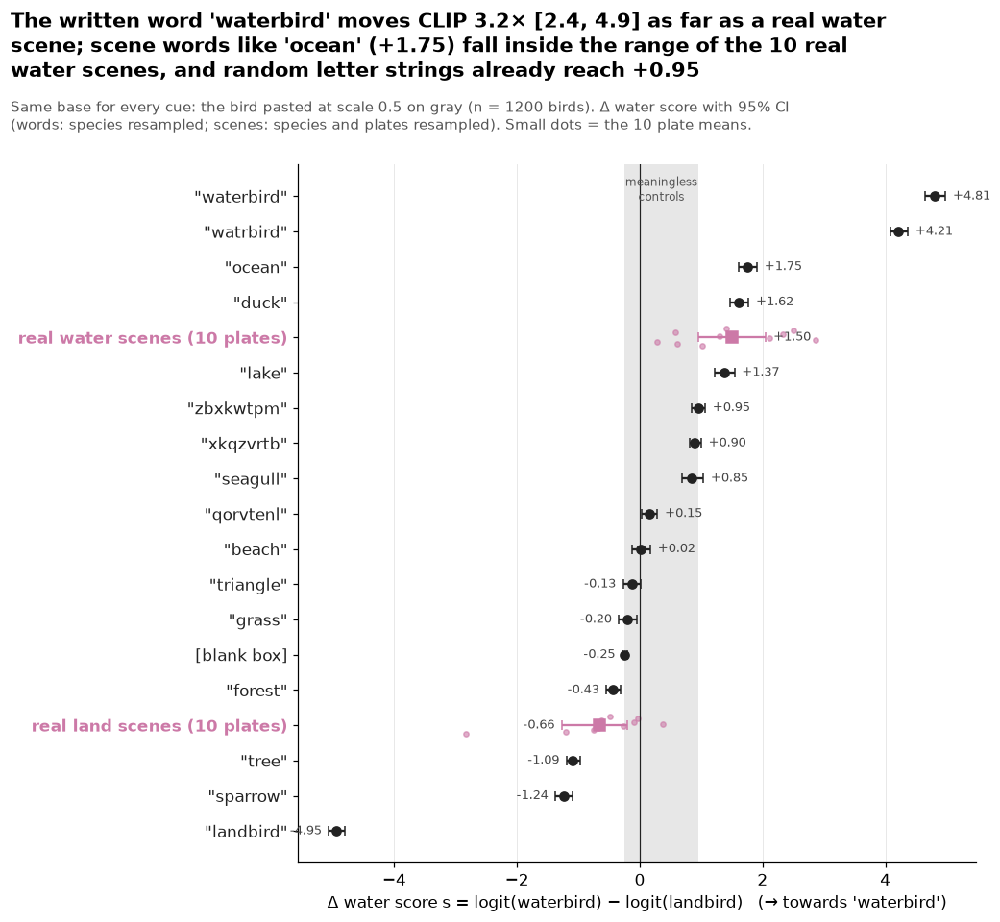

In [24]:
base5 = CUE[(CUE.cond == "paste_gray") & (CUE.scale == 0.5)].set_index("idx").s
rows = []
for w in ex.ALL_WORDS:
    v = CUE[(CUE.cond == "gword") & (CUE.word == w)].set_index("idx").s - base5
    e = st.cluster_boot_mean(v.to_numpy(), SPC.loc[v.index])
    rows.append(dict(cue=f'"{w}"', kind="word", d=e[0], lo=e[1], hi=e[2]))
for w in ["[blank box]", "qorvtenl", "zbxkwtpm"]:
    d_ = G2[(G2.scale == 0.5) & (G2["size"] == 0.08) & (G2.word == w)].set_index("idx").s - base5
    e = st.cluster_boot_mean(d_.to_numpy(), SPC.loc[d_.index])
    rows.append(dict(cue=w if w.startswith("[") else f'"{w}"', kind="word", d=e[0], lo=e[1], hi=e[2]))
SCENE_M = {}
for place, nm in [(1, "real water scenes (10 plates)"), (0, "real land scenes (10 plates)")]:
    M = plate_matrix(0.5, "water" if place == 1 else "land", value="s").sub(base5, axis=0)
    SCENE_M[place] = M
    e = st.two_way_boot_mean(M.to_numpy(), SPC.loc[M.index].to_numpy())
    rows.append(dict(cue=nm, kind="scene", d=e[0], lo=e[1], hi=e[2]))
WD = pd.DataFrame(rows).sort_values("d")
WD_i = WD.set_index("cue")
display(WD.round(2))
# ratio word / scene with a joint bootstrap (species of birds and plates resampled together)
wv = (CUE[(CUE.cond == "gword") & (CUE.word == "waterbird")].set_index("idx").s - base5).loc[SCENE_M[1].index].to_numpy()
Mw = SCENE_M[1].to_numpy(); sp_codes = pd.factorize(SPC.loc[SCENE_M[1].index].to_numpy())[0]
groups_ = [np.flatnonzero(sp_codes == k) for k in range(sp_codes.max() + 1)]
rng_r = np.random.default_rng(3); ratios = []
for _ in range(config.N_BOOT):
    rows_ = np.concatenate([groups_[k] for k in rng_r.integers(0, len(groups_), len(groups_))])
    cols_ = rng_r.integers(0, Mw.shape[1], Mw.shape[1])
    ratios.append(wv[rows_].mean() / Mw[np.ix_(rows_, cols_)].mean())
ratio = (wv.mean() / Mw.mean(), *np.quantile(ratios, [0.025, 0.975]))
plate_means = {p: SCENE_M[p].mean(axis=0).to_numpy() for p in (0, 1)}
ctrl_names = ['"triangle"', "[blank box]", '"qorvtenl"', '"zbxkwtpm"', '"xkqzvrtb"']
ctrl_rng = (WD_i.loc[ctrl_names].d.min(), WD_i.loc[ctrl_names].d.max())
print(f"'waterbird' / water scene = {ratio[0]:.2f} [{ratio[1]:.2f}, {ratio[2]:.2f}]; water plate means {np.round(np.sort(plate_means[1]), 2)}; "
      f"land plate means {np.round(np.sort(plate_means[0]), 2)}; control range {ctrl_rng[0]:+.2f} to {ctrl_rng[1]:+.2f}")

fig, ax = plt.subplots(figsize=(9.5, 7.4))
yy = np.arange(len(WD))
ax.axvspan(*ctrl_rng, color="#DDDDDD", alpha=0.7, lw=0)
ax.text(np.mean(ctrl_rng), len(WD) - 0.4, "meaningless\ncontrols", ha="center", va="top", fontsize=8, color="#555")
for y0, r in zip(yy, WD.itertuples()):
    c = style.CUE_COLORS["background"] if r.kind == "scene" else style.CUE_COLORS["text"]
    ax.errorbar(r.d, y0, xerr=[[r.d - r.lo], [r.hi - r.d]], fmt="o" if r.kind == "word" else "s", color=c, ms=8 if r.kind == "scene" else 6, capsize=3, zorder=3)
    if r.kind == "scene":
        pm = plate_means[1 if "water" in r.cue else 0]
        ax.scatter(pm, np.full(len(pm), y0) + np.linspace(-0.25, 0.25, len(pm)), s=12, color=c, alpha=0.6, zorder=2)
    ax.text((r.hi if r.d >= 0 else r.lo) + (0.12 if r.d >= 0 else -0.12), y0, f"{r.d:+.2f}", va="center", ha="left" if r.d >= 0 else "right", fontsize=8.5, color="#444")
ax.set_yticks(yy, WD.cue)
for t, k in zip(ax.get_yticklabels(), WD.kind):
    t.set_color(style.CUE_COLORS["background"] if k == "scene" else style.CUE_COLORS["text"]); t.set_fontweight("bold" if k == "scene" else "normal")
ax.axvline(0, color="#222", lw=0.8)
ax.set_xlabel("Δ water score s = logit(waterbird) − logit(landbird)   (→ towards 'waterbird')")
ax.grid(axis="y", visible=False)
fig.tight_layout()
oc = WD_i.loc['"ocean"']
assert ratio[1] > 2 and plate_means[1].min() <= oc.d <= plate_means[1].max() and ctrl_rng[1] > 0.5, "claims in the title"
style.suptitle(fig, f"The written word 'waterbird' moves CLIP {ratio[0]:.1f}× [{ratio[1]:.1f}, {ratio[2]:.1f}] as far as a real water scene; "
               f"scene words like 'ocean' (+{oc.d:.2f}) fall inside the range of the 10 real water scenes, and random letter strings already reach +{ctrl_rng[1]:.2f}",
               f"Same base for every cue: the bird pasted at scale 0.5 on gray (n = {len(base5)} birds). Δ water score with 95% CI "
               "(words: species resampled; scenes: species and plates resampled). Small dots = the 10 plate means.", wrap=80)
style.save(fig, "fig4d_word_vs_scene"); plt.show()

**Asymmetry: do water scenes pull harder?** Shares of wrong answers depend on where the decision threshold sits. So here we look at the class-free water score directly, against two references:
- **Gray reference:** Δs of the 10 water plates and the 10 land plates relative to the same bird on gray, per class and scale.
- **Reference-free swing:** s on water plates − s on land plates for the same bird and scale. It does not depend on where "neutral" is.

,label,scale,water_vs_gray,wg_lo,wg_hi,land_vs_gray,lg_lo,lg_hi,swing,sw_lo,sw_hi,gray_s,gray_lo,gray_hi
0,0,1.00,2.52,2.04,3.08,0.52,0.05,0.90,2.01,1.40,2.69,-2.98,-3.23,-2.75
1,0,0.80,2.50,1.98,3.07,0.47,-0.02,0.86,2.02,1.40,2.75,-2.59,-2.84,-2.34
2,0,0.65,2.35,1.85,2.89,0.28,-0.25,0.71,2.06,1.42,2.76,-2.06,-2.30,-1.83
3,0,0.50,2.26,1.77,2.79,0.12,-0.41,0.53,2.14,1.56,2.80,-1.56,-1.78,-1.35
4,0,0.40,2.22,1.73,2.74,-0.05,-0.59,0.38,2.28,1.62,2.96,-1.05,-1.26,-0.84
5,0,0.30,2.06,1.58,2.57,-0.56,-1.12,-0.08,2.61,1.94,3.32,-0.31,-0.50,-0.12
6,0,0.20,1.79,1.27,2.30,-1.11,-1.73,-0.61,2.89,2.11,3.59,0.36,0.24,0.48
7,0,0.15,1.82,1.29,2.34,-1.19,-1.82,-0.66,3.01,2.26,3.76,0.44,0.35,0.54
8,1,1.00,0.80,0.29,1.25,-0.99,-1.69,-0.45,1.79,1.10,2.54,2.72,2.39,3.07
9,1,0.80,0.80,0.25,1.33,-1.11,-1.81,-0.56,1.91,1.23,2.76,2.71,2.40,3.03


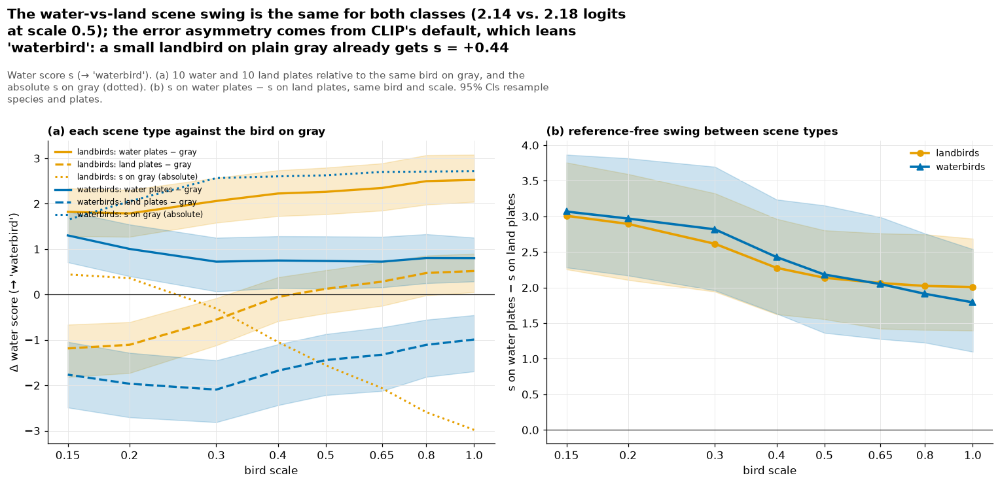

In [25]:
swing_rows = []
for lab in (0, 1):
    for s_ in ex.SCALES:
        Mw_ = plate_matrix(s_, "water", "s"); Ml_ = plate_matrix(s_, "land", "s")
        keep = Mw_.index[Mw_.index.isin(df.index[df.label == lab])]
        Mw_, Ml_ = Mw_.loc[keep], Ml_.loc[keep]
        g_s = CUE[(CUE.cond == "paste_gray") & (CUE.scale == s_)].set_index("idx").s.loc[keep]
        spk = SPC.loc[keep].to_numpy()
        e_w = st.two_way_boot_mean(Mw_.sub(g_s, axis=0).to_numpy(), spk, n_boot=NB)
        e_l = st.two_way_boot_mean(Ml_.sub(g_s, axis=0).to_numpy(), spk, n_boot=NB)
        # swing: resample species, and water and land plates independently
        codes = pd.factorize(spk)[0]; grp_ = [np.flatnonzero(codes == k) for k in range(codes.max() + 1)]
        rng_s = np.random.default_rng(int(100 * s_) + lab); bs = []
        A1, A2 = Mw_.to_numpy(), Ml_.to_numpy()
        for _ in range(NB):
            rr = np.concatenate([grp_[k] for k in rng_s.integers(0, len(grp_), len(grp_))])
            bs.append(A1[np.ix_(rr, rng_s.integers(0, 10, 10))].mean() - A2[np.ix_(rr, rng_s.integers(0, 10, 10))].mean())
        sw = A1.mean() - A2.mean()
        gst = st.cluster_boot_mean(g_s.to_numpy(), spk, n_boot=NB)
        swing_rows.append(dict(label=lab, scale=s_, water_vs_gray=e_w[0], wg_lo=e_w[1], wg_hi=e_w[2], land_vs_gray=e_l[0], lg_lo=e_l[1], lg_hi=e_l[2],
                               swing=sw, sw_lo=np.quantile(bs, 0.025), sw_hi=np.quantile(bs, 0.975), gray_s=gst[0], gray_lo=gst[1], gray_hi=gst[2]))
SW = pd.DataFrame(swing_rows)
display(SW.round(2))

fig, (ax, bx) = plt.subplots(1, 2, figsize=(14, 5.2), sharex=True)
for lab in (0, 1):
    d = SW[SW.label == lab]; col = style.CLASS_COLORS[lab]
    for key, ls, nm in [("water_vs_gray", "-", "water plates − gray"), ("land_vs_gray", "--", "land plates − gray")]:
        lo_, hi_ = ("wg_lo", "wg_hi") if key == "water_vs_gray" else ("lg_lo", "lg_hi")
        ax.plot(d.scale, d[key], ls=ls, color=col, lw=2.2, label=f"{CLASS_NAMES[lab]}s: {nm}")
        ax.fill_between(d.scale, d[lo_], d[hi_], color=col, alpha=0.2)
    ax.plot(d.scale, d.gray_s, ls=":", color=col, lw=2, label=f"{CLASS_NAMES[lab]}s: s on gray (absolute)")
    bx.plot(d.scale, d.swing, color=col, lw=2.4, marker=style.GROUP_MARKER[f"{CLASS_NAMES[lab]} / land"], label=f"{CLASS_NAMES[lab]}s")
    bx.fill_between(d.scale, d.sw_lo, d.sw_hi, color=col, alpha=0.2)
for a in (ax, bx):
    a.axhline(0, color="#222", lw=0.8); a.set_xscale("log"); a.set_xticks(ex.SCALES, [str(s) for s in ex.SCALES]); a.minorticks_off()
    a.set_xlabel("bird scale")
ax.set_ylabel("Δ water score (→ 'waterbird')"); ax.set_title("(a) each scene type against the bird on gray", fontsize=11)
bx.set_ylabel("s on water plates − s on land plates"); bx.set_title("(b) reference-free swing between scene types", fontsize=11)
ax.legend(fontsize=8, loc="upper left", ncol=1); bx.legend(fontsize=9)
fig.tight_layout()
sw5 = SW[SW.scale == 0.5].set_index("label"); g15 = SW[(SW.scale == min(ex.SCALES)) & (SW.label == 0)].iloc[0]
assert abs(sw5.loc[0, "swing"] - sw5.loc[1, "swing"]) < 0.5 and sw5.loc[0, "sw_lo"] < sw5.loc[1, "sw_hi"] and sw5.loc[1, "sw_lo"] < sw5.loc[0, "sw_hi"], \
    "claim: the swing is the same for both classes"
assert g15.gray_lo > 0, "claim: a small landbird on plain gray is already called waterbird"
style.suptitle(fig, f"The water-vs-land scene swing is the same for both classes ({sw5.loc[0, 'swing']:.2f} vs. {sw5.loc[1, 'swing']:.2f} logits at scale 0.5); "
               f"the error asymmetry comes from CLIP's default, which leans 'waterbird': a small landbird on plain gray already gets s = +{g15.gray_s:.2f}",
               "Water score s (→ 'waterbird'). (a) 10 water and 10 land plates relative to the same bird on gray, and the absolute s on gray (dotted). "
               "(b) s on water plates − s on land plates, same bird and scale. 95% CIs resample species and plates.", wrap=80)
style.save(fig, "fig4e_scene_asymmetry"); plt.show()

**Dose-matched comparison of word and scene.** The same base image again (bird pasted on gray at scale 1.0, 0.5 or 0.15). We count how many birds that are *correct on that base* become wrong under each cue: the conflicting scene (all 10 plates), the misleading word at 4%, 8% and 12% height, and the mean of the 4 neutral controls at the same size.

,label,scale,cue,size,n,share,lo,hi
0,0,1.00,conflicting scene,NaN,542,0.338,0.238,0.469
1,0,1.00,misleading word,0.04,542,0.952,0.930,0.969
2,0,1.00,neutral controls,0.04,542,0.024,0.016,0.033
3,0,1.00,misleading word,0.08,542,0.978,0.964,0.989
4,0,1.00,neutral controls,0.08,542,0.046,0.036,0.058
5,0,1.00,misleading word,0.12,542,0.994,0.987,1.000
6,0,1.00,neutral controls,0.12,542,0.019,0.011,0.028
7,0,0.50,conflicting scene,NaN,466,0.574,0.443,0.722
8,0,0.50,misleading word,0.04,466,1.000,1.000,1.000
9,0,0.50,neutral controls,0.04,466,0.069,0.051,0.084


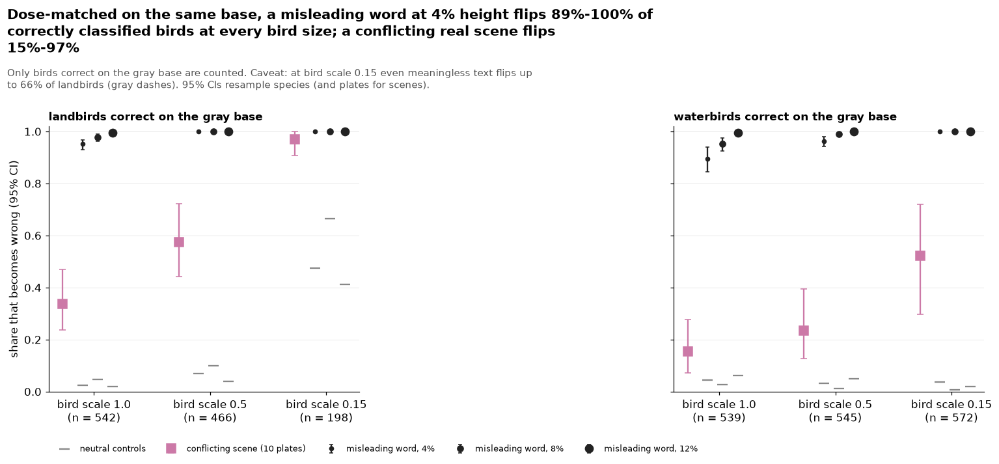

In [26]:
dose_rows = []
for lab in (0, 1):
    for s_ in ex.V2_WORD_SCALES:
        g0 = gray_m[s_]
        ok_ids = g0.index[(g0 > 0) & g0.index.isin(df.index[df.label == lab])]
        spk = SPC.loc[ok_ids].to_numpy()
        Mc = plate_matrix(s_, "conflicting").loc[ok_ids]
        e = st.two_way_boot_mean((Mc.to_numpy() < 0).astype(float), spk, n_boot=NB)
        dose_rows.append(dict(label=lab, scale=s_, cue="conflicting scene", size=np.nan, n=len(ok_ids), share=e[0], lo=e[1], hi=e[2]))
        for z in ex.V2_SIZES:
            mis, ctl = gword2(s_, z)
            for cname, v in [("misleading word", mis), ("neutral controls", None)]:
                if v is None:
                    dz = G2[(G2.scale == s_) & (G2["size"] == z) & G2.word.isin(ctrl_words)]
                    v = (dz.assign(w=lambda q: q.margin < 0).groupby("idx").w.mean())
                    vals = v.loc[ok_ids].to_numpy(float)
                else:
                    vals = (v.loc[ok_ids] < 0).to_numpy(float)
                e = st.cluster_boot_mean(vals, spk, n_boot=NB)
                dose_rows.append(dict(label=lab, scale=s_, cue=cname, size=z, n=len(ok_ids), share=e[0], lo=e[1], hi=e[2]))
DOSE = pd.DataFrame(dose_rows)
display(DOSE.round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 5.2), sharey=True)
xpos = {1.0: 0, 0.5: 1, 0.15: 2}
for ax, lab in zip(axes, (0, 1)):
    d = DOSE[DOSE.label == lab]
    sc_ = d[d.cue == "conflicting scene"]
    ax.errorbar([xpos[s] - 0.27 for s in sc_.scale], sc_.share, yerr=[sc_.share - sc_.lo, sc_.hi - sc_.share], fmt="s", ms=9,
                color=style.CUE_COLORS["background"], capsize=3, label="conflicting scene (10 plates)")
    for k_, z in enumerate(ex.V2_SIZES):
        mw = d[(d.cue == "misleading word") & (d["size"] == z)]
        nc = d[(d.cue == "neutral controls") & (d["size"] == z)]
        off = -0.1 + 0.13 * k_
        ax.errorbar([xpos[s] + off for s in mw.scale], mw.share, yerr=[mw.share - mw.lo, mw.hi - mw.share], fmt="o", ms=4 + 2 * k_,
                    color=style.CUE_COLORS["text"], capsize=2, label=f"misleading word, {int(100 * z)}%")
        ax.scatter([xpos[s] + off for s in nc.scale], nc.share, marker="_", s=120, color="#888", label="neutral controls" if k_ == 0 else None)
    ax.set_xticks(list(xpos.values()), [f"bird scale {s}\n(n = {int(d[(d.scale == s) & (d.cue == 'conflicting scene')].n.iloc[0])})" for s in xpos])
    ax.set_title(f"{CLASS_NAMES[lab]}s correct on the gray base", fontsize=11); ax.set_ylim(0, 1.02); ax.grid(axis="x", visible=False)
axes[0].set_ylabel("share that becomes wrong (95% CI)")
axes[0].legend(fontsize=8.5, loc="upper left", bbox_to_anchor=(0, -0.17), ncol=5)
fig.tight_layout()
w4 = DOSE[(DOSE.cue == "misleading word") & (DOSE["size"] == 0.04)].set_index(["label", "scale"])
scn = DOSE[DOSE.cue == "conflicting scene"].set_index(["label", "scale"])
ctl_max = DOSE[DOSE.cue == "neutral controls"].groupby(["label", "scale"]).share.max()
assert all(w4.loc[k, "share"] >= scn.loc[k, "hi"] for k in scn.index), "claim: the 4% word beats the scene at every bird size"
style.suptitle(fig, f"Dose-matched on the same base, a misleading word at 4% height flips {pct(w4.share.min(), 0)}-{pct(w4.share.max(), 0)} of correctly "
               f"classified birds at every bird size; a conflicting real scene flips {pct(scn.share.min(), 0)}-{pct(scn.share.max(), 0)}",
               f"Only birds correct on the gray base are counted. Caveat: at bird scale 0.15 even meaningless text flips up to "
               f"{pct(ctl_max.loc[(0, 0.15)], 0)} of landbirds (gray dashes). 95% CIs resample species (and plates for scenes).", wrap=80)
style.save(fig, "fig4f_word_vs_scene_dose_matched"); plt.show()

In [27]:
d_lb = SW[SW.label == 0].set_index("scale"); d_wb = SW[SW.label == 1].set_index("scale")
md(f"""**Finding.**
1. **Bird and background add up.** The water score of an original image is close to the sum of its parts: s(orig) ≈ {coef[0]:.2f}·s(bird only) + {coef[1]:.2f}·s(background only) + {coef[2]:.2f} (R² = {r2:.2f}, n = {len(W)}). When the two disagree, the bird wins {pct(fbird[0])} [{pct(fbird[1])}, {pct(fbird[2])}] of the time. The fitted intercept (+{coef[2]:.2f} [{bc[0, 2]:.2f}, {bc[1, 2]:.2f}]) puts the decision boundary on the waterbird side, so landbirds need more bird evidence to be classified correctly.
2. **Scenes act symmetrically; CLIP's default does not.** Swapping a land scene for a water scene moves the score by the same amount for both classes ({d_lb.loc[0.5, 'swing']:.2f} vs. {d_wb.loc[0.5, 'swing']:.2f} logits at scale 0.5; {d_lb.loc[0.15, 'swing']:.2f} vs. {d_wb.loc[0.15, 'swing']:.2f} at 0.15). The error asymmetry (landbirds on water fail far more often than waterbirds on land) comes from where CLIP starts: a small landbird on plain gray already gets s = +{g15.gray_s:.2f}, i.e. it is called waterbird. On conflicting plates, landbirds go from {pct(w_conf[0][0][0])} wrong at full size to {pct(w_conf[0][1][0])} at scale {min(ex.SCALES)}; waterbirds from {pct(w_conf[1][0][0])} to {pct(w_conf[1][1][0])} (all 10 plates, CIs resample species and plates).
3. **A word beats a scene, at every dose.** On the same base, a misleading class word at 4% height flips {pct(w4.share.min())}-{pct(w4.share.max())} of the birds that were correct, while a conflicting real scene flips {pct(scn.share.min())}-{pct(scn.share.max())} depending on bird size. The written word "waterbird" moves the score {ratio[0]:.1f}× [{ratio[1]:.1f}, {ratio[2]:.1f}] as far as a real water scene. Scene words ("ocean" +{oc.d:.2f}, "duck" +{WD_i.loc['"duck"'].d:.2f}, "lake" +{WD_i.loc['"lake"'].d:.2f}) fall inside the range of the 10 real water scenes (+{plate_means[1].min():.2f} to +{plate_means[1].max():.2f}). Meaningless text is not neutral either: random letter strings push towards water by up to +{ctrl_rng[1]:.2f}, and at the smallest bird size neutral text flips up to {pct(ctl_max.loc[(0, 0.15)])} of landbirds.
4. **One shared weakness, not two separate shortcuts.** Birds that conflicting scenes fool are also fooled by words (ρ = {RHO[(0, 'fooled')][0]:.2f} [{RHO[(0, 'fooled')][1]:.2f}, {RHO[(0, 'fooled')][2]:.2f}] landbirds, {RHO[(1, 'fooled')][0]:.2f} [{RHO[(1, 'fooled')][1]:.2f}, {RHO[(1, 'fooled')][2]:.2f}] waterbirds). On one shared base the cue-specific shifts correlate as well ({RHO[(0, 'shift')][0]:.2f} / {RHO[(1, 'shift')][0]:.2f}). Both track how weakly the bird itself is recognised. Our first draft said the opposite ("two separate shortcuts"), based on a margin-loss measure on different base images; the critique at check-in 5 caught it.""")

**Finding.**
1. **Bird and background add up.** The water score of an original image is close to the sum of its parts: s(orig) ≈ 0.67·s(bird only) + 0.65·s(background only) + 0.31 (R² = 0.83, n = 1200). When the two disagree, the bird wins 65.4% [60.7%, 70.0%] of the time. The fitted intercept (+0.31 [0.22, 0.41]) puts the decision boundary on the waterbird side, so landbirds need more bird evidence to be classified correctly.
2. **Scenes act symmetrically; CLIP's default does not.** Swapping a land scene for a water scene moves the score by the same amount for both classes (2.14 vs. 2.18 logits at scale 0.5; 3.01 vs. 3.07 at 0.15). The error asymmetry (landbirds on water fail far more often than waterbirds on land) comes from where CLIP starts: a small landbird on plain gray already gets s = +0.44, i.e. it is called waterbird. On conflicting plates, landbirds go from 39.8% wrong at full size to 98.5% at scale 0.15; waterbirds from 21.5% to 53.4% (all 10 plates, CIs resample species and plates).
3. **A word beats a scene, at every dose.** On the same base, a misleading class word at 4% height flips 89.4%-100.0% of the birds that were correct, while a conflicting real scene flips 15.5%-97.1% depending on bird size. The written word "waterbird" moves the score 3.2× [2.4, 4.9] as far as a real water scene. Scene words ("ocean" +1.75, "duck" +1.62, "lake" +1.37) fall inside the range of the 10 real water scenes (+0.28 to +2.87). Meaningless text is not neutral either: random letter strings push towards water by up to +0.95, and at the smallest bird size neutral text flips up to 66.4% of landbirds.
4. **One shared weakness, not two separate shortcuts.** Birds that conflicting scenes fool are also fooled by words (ρ = 0.39 [0.32, 0.46] landbirds, 0.32 [0.23, 0.40] waterbirds). On one shared base the cue-specific shifts correlate as well (0.19 / 0.33). Both track how weakly the bird itself is recognised. Our first draft said the opposite ("two separate shortcuts"), based on a margin-loss measure on different base images; the critique at check-in 5 caught it.

In [28]:
md(f"""**Limitation.** Edited images are not natural photos. Pasted birds have hard edges, the "background only" images keep an inpainting smudge where the bird was (its effect is not calibrated), and the scenes come from only 10 plates per type, which is why scene CIs resample plates. The gray canvas is not a neutral reference: it already leans "waterbird" for small birds. Words are always black on a white box in one font. The canvas we edit (crop, then resize) differs slightly from CLIP's own preprocessing (resize, then crop): {pct(1 - ((orig > 0) == (ref > 0)).mean())} of the unedited canvases get a different prediction than the original image, so all effects are measured against the unedited canvas. The sample is balanced ({PER_GROUP} per group) and restricted to clean masks, so shares are not test-set rates.""")

**Limitation.** Edited images are not natural photos. Pasted birds have hard edges, the "background only" images keep an inpainting smudge where the bird was (its effect is not calibrated), and the scenes come from only 10 plates per type, which is why scene CIs resample plates. The gray canvas is not a neutral reference: it already leans "waterbird" for small birds. Words are always black on a white box in one font. The canvas we edit (crop, then resize) differs slightly from CLIP's own preprocessing (resize, then crop): 1.5% of the unedited canvases get a different prediction than the original image, so all effects are measured against the unedited canvas. The sample is balanced (300 per group) and restricted to clean masks, so shares are not test-set rates.

## 5. Overview projection of CLIP's *outputs*

**Question.** Do the errors form a few distinct regions of behaviour, and what sets those regions apart?

**Method.** Each image is described by its **output** vector: CLIP's logits for 200 species prompts plus 30 scene/context prompts (230 numbers; no embeddings). Each image's mean logit is subtracted (CLIP gives some images higher similarities to everything), and each prompt is then z-scored across images so all prompts count equally.
- **Map:** UMAP (cosine, n_neighbors = 30, min_dist = 0.1) maps the 230-d vectors to 2-d for display.
- **Is the map stable?** 3 seeds × 2 settings. For each run we measure what fraction of each image's 15 nearest neighbours in the main run it keeps. Our first draft clustered on the 2-d map with HDBSCAN. That turned out unstable (see the AI log), so:
- **Clusters are found in the full 230-d space,** not on the map: k-means on the first 30 principal components (93% of the variance). k is chosen by stability alone (agreement between solutions on 80% subsamples), *before* looking at error rates. Every cluster gets a bootstrap Jaccard stability (20 subsamples). An **error cluster** is a cluster with *more errors than its bird/background mix predicts*: each image's expected error is the error rate of its class × background group, and the cluster's mean excess over that must have a CI above 0 (species resampled). It must also have Jaccard ≥ 0.6. Our first draft compared clusters with the overall error rate. That mostly re-found the landbird/water group, which the group label alone separates better (critique at check-in 5).
- **Drill-down:** for error clusters we compare composition (group, species, water rating, bird size from the mask) and which *scene prompts* score unusually high, then check against thumbnails.
- **Second view:** an independent image encoder (DINOv2-small, CLS vector). It shows which images look alike *to a different model*. This is an input description, not CLIP's internals.

In [29]:
import umap
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score
from sklearn.neighbors import NearestNeighbors
X = np.concatenate([L[:, SL_SP], L[:, SL_SCENE]], axis=1)
X = X - X.mean(axis=1, keepdims=True)
X = (X - X.mean(axis=0)) / X.std(axis=0)
SCENE_COLS = list(range(len(SPECIES), X.shape[1]))

def run_umap(Z, seed=0, nn=30, md_=0.1, tag="clipout"):
    p = config.CACHE_DIR / f"umap_{tag}_s{seed}_nn{nn}_md{md_}.npy"
    if p.exists():
        return np.load(p)
    E = umap.UMAP(n_neighbors=nn, min_dist=md_, metric="cosine", random_state=seed).fit_transform(Z)
    np.save(p, E); return E

E = run_umap(X)
df["ux"], df["uy"] = E[:, 0], E[:, 1]

def knn_sets(A, k=15):
    return NearestNeighbors(n_neighbors=k + 1).fit(A).kneighbors(A, return_distance=False)[:, 1:]

def knn_overlap(A, B, k=15):
    ia, ib = knn_sets(A, k), knn_sets(B, k)
    return float(np.mean([len(set(a) & set(b)) / k for a, b in zip(ia, ib)]))

runs = {(s, nn, mdv): run_umap(X, s, nn, mdv) for s in (0, 1, 2) for nn, mdv in [(30, 0.1), (15, 0.5)]}
stab = pd.DataFrame([dict(seed=s, n_neighbors=nn, min_dist=mdv, knn15_kept_vs_main=knn_overlap(E, R))
                     for (s, nn, mdv), R in runs.items() if (s, nn, mdv) != (0, 30, 0.1)])
display(stab.round(3))
print(f"15-NN of the 230-d space kept in the main 2-d map: {knn_overlap(X, E):.3f}")

,seed,n_neighbors,min_dist,knn15_kept_vs_main
0,0,15,0.5,0.200
1,1,30,0.1,0.327
2,1,15,0.5,0.203
3,2,30,0.1,0.328
4,2,15,0.5,0.201


15-NN of the 230-d space kept in the main 2-d map: 0.172


In [30]:
pca = PCA(30, random_state=0).fit(X)
Zp = pca.transform(X)
print(f"30 principal components explain {pct(pca.explained_variance_ratio_.sum())} of the variance")
ksel = []
for k in (6, 8, 10, 12, 16):
    base_l = KMeans(k, n_init=10, random_state=0).fit_predict(Zp)
    rng_k = np.random.default_rng(k); aris = []
    for b in range(5):
        j = rng_k.choice(len(Zp), int(0.8 * len(Zp)), replace=False)
        aris.append(adjusted_rand_score(base_l, KMeans(k, n_init=10, random_state=b).fit(Zp[j]).predict(Zp)))
    ksel.append(dict(k=k, subsample_ARI=np.mean(aris)))
ksel = pd.DataFrame(ksel); display(ksel.round(3))
K = int(ksel[ksel.k >= 8].sort_values("subsample_ARI", ascending=False).k.iloc[0])   # rule: most stable k with at least 8 clusters
km = KMeans(K, n_init=10, random_state=0).fit(Zp)
df["cluster"] = km.labels_
# per-cluster bootstrap Jaccard (Hennig 2007): best match of each cluster in 20 subsample solutions
jac = np.zeros((20, K)); rng_j = np.random.default_rng(1)
for b in range(20):
    j = rng_j.choice(len(Zp), int(0.8 * len(Zp)), replace=False)
    lb = KMeans(K, n_init=5, random_state=100 + b).fit(Zp[j]).predict(Zp[j])
    la = km.labels_[j]
    for c in range(K):
        A = set(np.flatnonzero(la == c))
        jac[b, c] = max(len(A & set(np.flatnonzero(lb == d))) / len(A | set(np.flatnonzero(lb == d))) for d in range(K))
overall_err = 1 - df.correct.mean()
# Expected error of each image from its class x background group alone (indirect standardisation).
# A cluster is an *error cluster* only if it has more errors than its group mix predicts (critique at check-in 5).
grp_err = 1 - df.groupby("group").correct.mean()
df["exp_err"] = df.group.map(grp_err)
crows = []
for c, d in df.groupby("cluster"):
    e = st.cluster_boot_mean((1 - d.correct).to_numpy(float), d.species)
    x = st.cluster_boot_mean((1 - d.correct - d.exp_err).to_numpy(float), d.species)
    crows.append(dict(cluster=c, n=len(d), err=e[0], lo=e[1], hi=e[2], expected=d.exp_err.mean(), excess=x[0], ex_lo=x[1], ex_hi=x[2],
                      jaccard=jac[:, c].mean(), water_bg=d.place.mean(),
                      waterbird=d.label.mean(), main_group=d.group.value_counts().index[0],
                      main_group_share=d.group.value_counts(normalize=True).iloc[0],
                      top_species=", ".join(d.species.value_counts().index[:3]), med_mask_area=d.mask_area.median(),
                      water_rating=d.water_rating.mean()))
clu = pd.DataFrame(crows).sort_values("excess", ascending=False)
clu["error_cluster"] = (clu.ex_lo > 0) & (clu.jaccard >= 0.6)
print(f"k = {K}; overall error rate {pct(overall_err)}; error clusters = excess-error CI above 0 and Jaccard >= 0.6")
display(clu.round(3))
# trivial baseline: how strongly does the group label alone concentrate errors?
lbw_m = (df.group == "landbird / water")
lift_group = ((lbw_m & (df.correct == 0)).sum() / (df.correct == 0).sum()) / lbw_m.mean()
print(f"group-label baseline: landbird/water holds {pct((lbw_m & (df.correct == 0)).sum() / (df.correct == 0).sum())} of the errors "
      f"in {pct(lbw_m.mean())} of the images (lift {lift_group:.2f})")
# do the 230-d clusters stay together in every UMAP layout? share of 2-d 15-NN in the same cluster
lab_arr = df.cluster.to_numpy()
coh = {f"seed {s}, nn {nn}, md {mdv}": float(np.mean(lab_arr[knn_sets(R)] == lab_arr[:, None])) for (s, nn, mdv), R in runs.items()}
print("share of 2-d neighbours in the same 230-d cluster, per UMAP run:", {k_: round(v, 2) for k_, v in coh.items()})

30 principal components explain 93.4% of the variance


,k,subsample_ARI
0,6,0.921
1,8,0.679
2,10,0.899
3,12,0.749
4,16,0.686


k = 10; overall error rate 29.0%; error clusters = excess-error CI above 0 and Jaccard >= 0.6


,cluster,n,err,lo,hi,expected,excess,ex_lo,ex_hi,jaccard,water_bg,waterbird,main_group,main_group_share,top_species,med_mask_area,water_rating,error_cluster
3,3,593,0.438,0.391,0.487,0.231,0.208,0.164,0.253,0.837,0.239,0.218,landbird / land,0.565,"Chuck_will_Widow, Winter_Wren, Cactus_Wren",0.140,1.042,True
4,4,696,0.397,0.294,0.520,0.251,0.145,0.087,0.215,0.887,0.777,0.596,waterbird / water,0.405,"Horned_Grebe, Brown_Pelican, Pied_billed_Grebe",0.182,2.068,True
9,9,717,0.593,0.547,0.642,0.486,0.107,0.060,0.156,0.769,0.891,0.075,landbird / water,0.854,"Black_and_white_Warbler, Gray_crowned_Rosy_Fin...",0.181,0.664,True
0,0,509,0.387,0.341,0.431,0.288,0.099,0.056,0.145,0.887,0.367,0.169,landbird / land,0.473,"Bronzed_Cowbird, Brewer_Blackbird, Common_Raven",0.184,1.004,True
6,6,560,0.216,0.143,0.326,0.180,0.036,-0.004,0.097,0.867,0.682,0.780,waterbird / water,0.479,"California_Gull, Glaucous_winged_Gull, Ivory_Gull",0.180,2.441,False
8,8,645,0.177,0.145,0.212,0.220,-0.043,-0.077,-0.006,0.774,0.208,0.085,landbird / land,0.707,"Sayornis, Loggerhead_Shrike, Black_billed_Cuckoo",0.154,0.654,False
1,1,450,0.393,0.345,0.439,0.490,-0.097,-0.146,-0.050,0.747,0.860,0.007,landbird / water,0.860,"Hooded_Oriole, Scott_Oriole, Common_Yellowthroat",0.167,0.438,False
7,7,445,0.117,0.087,0.147,0.271,-0.154,-0.193,-0.108,0.893,0.339,0.022,landbird / land,0.638,"Vermilion_Flycatcher, Scarlet_Tanager, Summer_...",0.158,0.285,False
5,5,648,0.071,0.049,0.096,0.261,-0.190,-0.211,-0.167,0.919,0.319,0.005,landbird / land,0.676,"Henslow_Sparrow, Lincoln_Sparrow, Le_Conte_Spa...",0.175,0.492,False
2,2,531,0.023,0.010,0.036,0.227,-0.204,-0.221,-0.188,0.779,0.239,0.004,landbird / land,0.757,"Pine_Warbler, Yellow_throated_Vireo, Wilson_Wa...",0.159,0.379,False


group-label baseline: landbird/water holds 75.2% of the errors in 39.7% of the images (lift 1.89)
share of 2-d neighbours in the same 230-d cluster, per UMAP run: {'seed 0, nn 30, md 0.1': 0.67, 'seed 0, nn 15, md 0.5': 0.63, 'seed 1, nn 30, md 0.1': 0.69, 'seed 1, nn 15, md 0.5': 0.63, 'seed 2, nn 30, md 0.1': 0.68, 'seed 2, nn 15, md 0.5': 0.62}


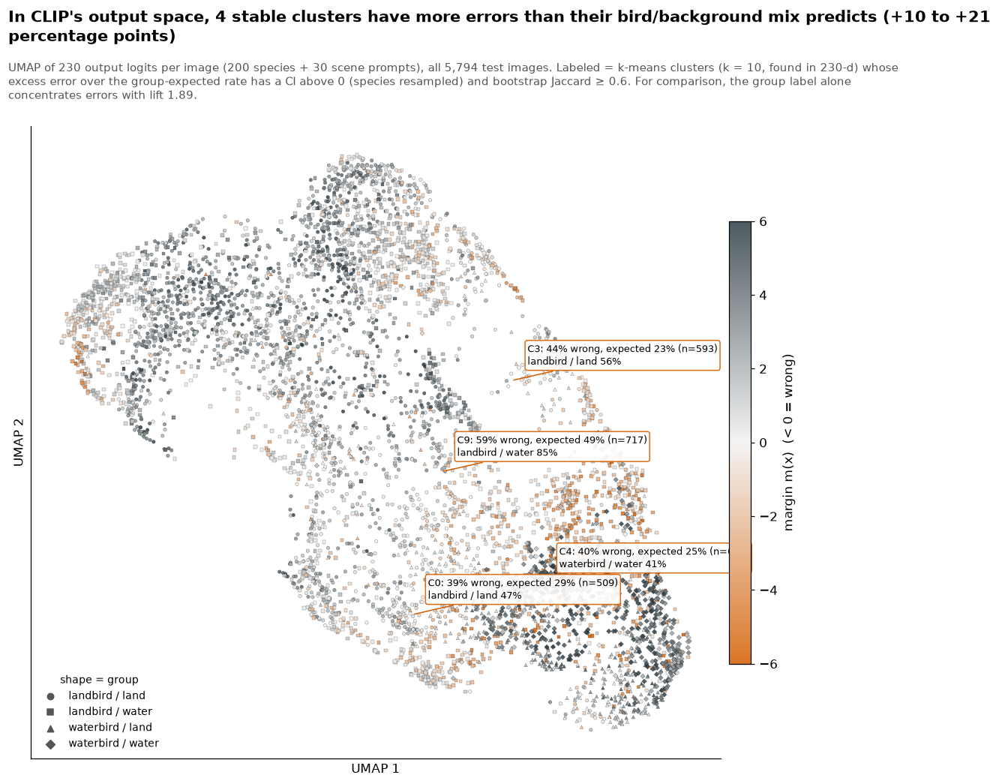

In [31]:
fig, ax = plt.subplots(figsize=(10.5, 8.2))
norm = plt.matplotlib.colors.TwoSlopeNorm(vmin=-6, vcenter=0, vmax=6)
for g in style.GROUPS:
    d = df[df.group == g]
    sc = ax.scatter(d.ux, d.uy, c=d.margin, cmap=style.MARGIN_CMAP, norm=norm, s=9, marker=style.GROUP_MARKER[g],
                    lw=0.15, edgecolors="#00000040", alpha=0.85)
cb = fig.colorbar(sc, ax=ax, shrink=0.7, pad=0.01); cb.set_label("margin m(x)  (< 0 = wrong)")
for r in clu[clu.error_cluster].itertuples():
    d = df[df.cluster == r.cluster]
    ax.annotate(f"C{r.cluster}: {pct(r.err, 0)} wrong, expected {pct(r.expected, 0)} (n={r.n})\n{r.main_group} {pct(r.main_group_share, 0)}",
                (d.ux.median(), d.uy.median()), xytext=(14, 14), textcoords="offset points", fontsize=8.5,
                bbox=dict(boxstyle="round,pad=0.25", fc="white", ec=style.ERROR, lw=1, alpha=0.9),
                arrowprops=dict(arrowstyle="-", color=style.ERROR))
for g in style.GROUPS:
    ax.scatter([], [], marker=style.GROUP_MARKER[g], color="#555", s=30, label=g)
ax.legend(loc="lower left", fontsize=9, title="shape = group", title_fontsize=9)
ax.set_xticks([]); ax.set_yticks([]); ax.grid(False); ax.set_xlabel("UMAP 1"); ax.set_ylabel("UMAP 2")
fig.tight_layout()
ecl = clu[clu.error_cluster].cluster.tolist()
in_ecl = df.cluster.isin(ecl)
err_share = (in_ecl & (df.correct == 0)).sum() / (df.correct == 0).sum()
ex_rng = clu[clu.error_cluster].excess
style.suptitle(fig, f"In CLIP's output space, {len(ecl)} stable clusters have more errors than their bird/background mix predicts "
               f"(+{100 * ex_rng.min():.0f} to +{100 * ex_rng.max():.0f} percentage points)",
               f"UMAP of 230 output logits per image (200 species + 30 scene prompts), all 5,794 test images. Labeled = k-means clusters (k = {K}, found in 230-d) "
               f"whose excess error over the group-expected rate has a CI above 0 (species resampled) and bootstrap Jaccard ≥ 0.6. "
               f"For comparison, the group label alone concentrates errors with lift {lift_group:.2f}.")
style.save(fig, "fig5_projection_clip_outputs"); plt.show()

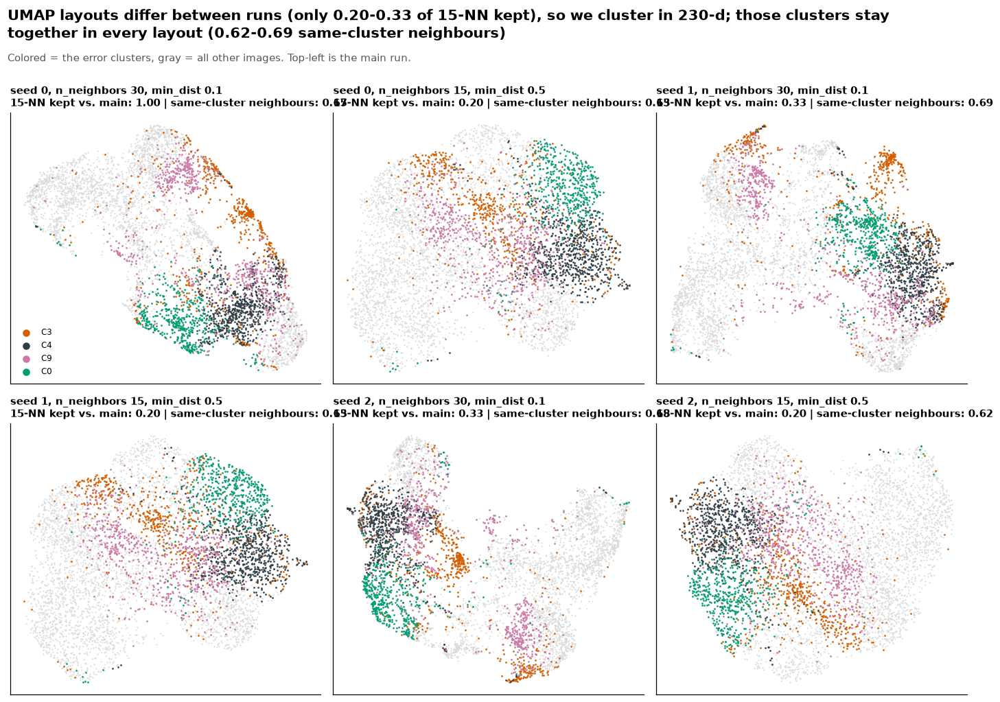

In [32]:
cl_cmap = plt.matplotlib.colors.ListedColormap(["#BBBBBB"] * K)
fig, axes = plt.subplots(2, 3, figsize=(13, 8.4))
for ax, ((s, nn, mdv), R) in zip(axes.flat, runs.items()):
    ax.scatter(R[:, 0], R[:, 1], c="#D9D9D9", s=2, lw=0, rasterized=True)
    for k_, c in enumerate(ecl):
        m = lab_arr == c
        ax.scatter(R[m, 0], R[m, 1], s=3, lw=0, color=[style.ERROR, "#2F3E46", style.CUE_COLORS["background"], style.CUE_COLORS["bird"], "#56B4E9", "#E69F00"][k_ % 6], label=f"C{c}", rasterized=True)
    kept = 1.0 if (s, nn, mdv) == (0, 30, 0.1) else stab[(stab.seed == s) & (stab.n_neighbors == nn) & (stab.min_dist == mdv)].knn15_kept_vs_main.iloc[0]
    ax.set_title(f"seed {s}, n_neighbors {nn}, min_dist {mdv}\n15-NN kept vs. main: {kept:.2f} | same-cluster neighbours: {coh[f'seed {s}, nn {nn}, md {mdv}']:.2f}", fontsize=9.5)
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
axes[0, 0].legend(loc="lower left", fontsize=8, markerscale=4)
fig.tight_layout()
assert stab.knn15_kept_vs_main.max() < 0.5 and min(coh.values()) > 0.6, "claims: layouts differ, clusters stay together"
style.suptitle(fig, f"UMAP layouts differ between runs (only {stab.knn15_kept_vs_main.min():.2f}-{stab.knn15_kept_vs_main.max():.2f} of 15-NN kept), "
               f"so we cluster in 230-d; those clusters stay together in every layout ({min(coh.values()):.2f}-{max(coh.values()):.2f} same-cluster neighbours)",
               "Colored = the error clusters, gray = all other images. Top-left is the main run.")
style.save(fig, "fig5b_projection_stability"); plt.show()

**Drill-down into the error clusters.** For each error cluster we list the scene prompts whose (centered, z-scored) logits are highest relative to all other images. This is CLIP's own output telling us what it "sees" there. Random member thumbnails let us check that description by eye.

all images: median mask area 0.170, mean water rating 0.98


,cluster,n,error,jaccard,group,water_bg,top_scene_prompts,top_species,mean_water_rating,median_mask_area
0,3,593,0.438,0.84,landbird / land (56%),24%,"broadleaf forest (+1.6 sd), forest (+1.5 sd), ...","Chuck_will_Widow, Winter_Wren, Cactus_Wren",1.04,0.140
1,4,696,0.397,0.89,waterbird / water (41%),78%,"waves (+1.3 sd), bird swimming (+1.3 sd), lake...","Horned_Grebe, Brown_Pelican, Pied_billed_Grebe",2.07,0.182
2,9,717,0.593,0.77,landbird / water (85%),89%,"the ocean (+0.5 sd), beach (+0.4 sd), bird swi...","Black_and_white_Warbler, Gray_crowned_Rosy_Fin...",0.66,0.181
3,0,509,0.387,0.89,landbird / land (47%),37%,"dark photo of bird (+1.3 sd), black and white ...","Bronzed_Cowbird, Brewer_Blackbird, Common_Raven",1.00,0.184


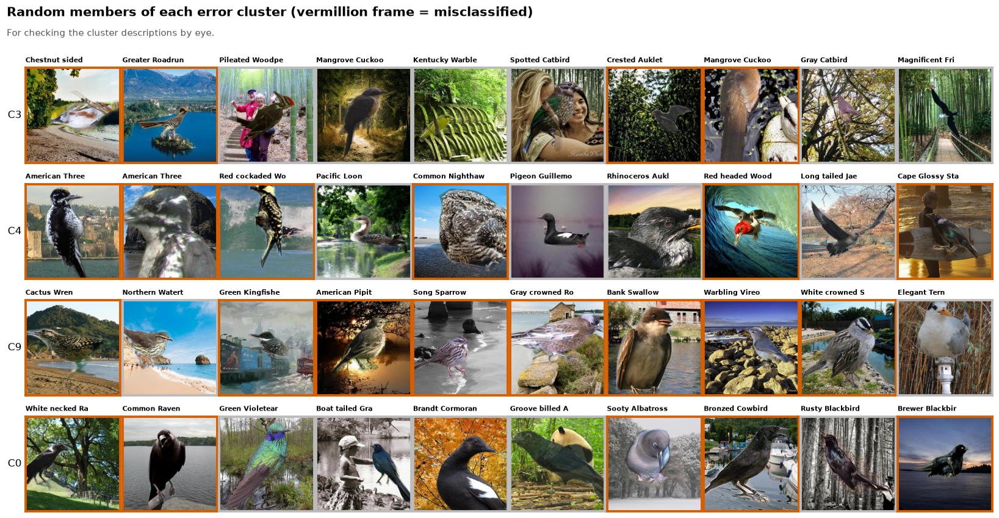

In [33]:
scene_names = [p.replace("a photo of ", "").replace("a ", "").rstrip(".") for p in SCENE_PROMPTS]
Zs = X[:, SCENE_COLS]
prof = []
for r in clu[clu.error_cluster].itertuples():
    m = (df.cluster == r.cluster).to_numpy()
    diff = Zs[m].mean(0) - Zs[~m].mean(0)
    top = np.argsort(diff)[::-1][:4]
    prof.append(dict(cluster=r.cluster, n=r.n, error=round(r.err, 3), jaccard=round(r.jaccard, 2), group=f"{r.main_group} ({pct(r.main_group_share, 0)})",
                     water_bg=pct(r.water_bg, 0), top_scene_prompts=", ".join(f"{scene_names[t]} (+{diff[t]:.1f} sd)" for t in top),
                     top_species=r.top_species, mean_water_rating=round(r.water_rating, 2), median_mask_area=round(r.med_mask_area, 3)))
prof = pd.DataFrame(prof)
print(f"all images: median mask area {df.mask_area.median():.3f}, mean water rating {df.water_rating.mean():.2f}")
display(prof)

fig, axes = plt.subplots(len(ecl), 10, figsize=(15, 1.7 * len(ecl) + 0.4))
axes = np.atleast_2d(axes)
for r_, c in enumerate(ecl):
    members = df.index[df.cluster == c]
    pick = np.random.default_rng(c).choice(members, min(10, len(members)), replace=False)
    for k_, i in enumerate(pick):
        ax = axes[r_, k_]; ax.imshow(CANV[i]); ax.set_xticks([]); ax.set_yticks([])
        for sp_ in ax.spines.values():
            sp_.set_visible(True); sp_.set_color(style.ERROR if df.correct[i] == 0 else "#BBBBBB"); sp_.set_linewidth(2.5)
        ax.set_title(species_display(df.species[i])[:15], fontsize=7)
    axes[r_, 0].set_ylabel(f"C{c}", rotation=0, ha="right", va="center", fontsize=11)
fig.tight_layout(w_pad=0.2)
style.suptitle(fig, "Random members of each error cluster (vermillion frame = misclassified)", "For checking the cluster descriptions by eye.")
style.save(fig, "fig5c_error_cluster_members", svg=False, dpi=110); plt.show()

**Second view: an independent image encoder.** DINOv2-small (self-supervised, never trained with text) gives each image a 384-d CLS vector. These vectors are not CLIP's and describe only the *inputs*.

We compare spaces with a k-NN test: for each image, the share of its 15 nearest neighbours that have property P (error, CLIP's prediction, water background, waterbird), scored as an AUC for predicting the image's own P. Errors are defined by CLIP's own score, and the 230 output logits nearly reproduce that score. So we also test CLIP's output space **with the water score s regressed out of every column**, and report the AUC **within each class × background group** (averaged). Without these two controls the test mostly measures that CLIP's outputs encode CLIP's prediction (critique at check-in 5). CIs resample species.

In [34]:
from transformers import AutoImageProcessor, AutoModel
dino_p = config.CACHE_DIR / "dinov2_small_cls.npy"
if dino_p.exists():
    D = np.load(dino_p)
else:
    dproc = AutoImageProcessor.from_pretrained("facebook/dinov2-small")
    dmod = AutoModel.from_pretrained("facebook/dinov2-small").to(scorer.device).eval()
    outs = []
    with torch.no_grad():
        for i in range(0, len(ds), 128):
            px = dproc(images=[im.convert("RGB") for im in ds[i:i + 128]["image"]], return_tensors="pt")["pixel_values"].to(scorer.device)
            outs.append(dmod(pixel_values=px).last_hidden_state[:, 0].float().cpu().numpy())
    D = np.concatenate(outs); np.save(dino_p, D)
    del dmod; torch.cuda.empty_cache()
ED = run_umap(D, tag="dinov2")
df["dx"], df["dy"] = ED[:, 0], ED[:, 1]

from aivis.analysis import auc, species_resamples
A_s = np.column_stack([df.s.to_numpy(), np.ones(len(df))])
X_res = X - A_s @ np.linalg.lstsq(A_s, X, rcond=None)[0]          # CLIP outputs with the water score removed

def nn_shares(Z, prop, k=15):
    nn = NearestNeighbors(n_neighbors=k + 1, metric="cosine").fit(Z).kneighbors(Z, return_distance=False)[:, 1:]
    return prop[nn].mean(axis=1)

err_v = (1 - df.correct).to_numpy(); g_v = df.group.to_numpy()
PROPS = {"error": err_v, "CLIP's prediction": df.pred.to_numpy(), "water background": df.place.to_numpy(), "waterbird (class)": df.label.to_numpy()}
SPACES = {"CLIP outputs (230 logits)": X, "CLIP outputs, score s removed": X_res, "DINOv2-small CLS (384-d)": D}
resamples = list(species_resamples(df.species.to_numpy(), n_boot=500))
def auc_ci(sh, pv, groups=None):
    def f(j):
        if groups is None:
            return auc(sh[j][pv[j] == 1], sh[j][pv[j] == 0])
        return np.nanmean([auc(sh[j][(groups[j] == x) & (pv[j] == 1)], sh[j][(groups[j] == x) & (pv[j] == 0)]) for x in pd.unique(groups)])
    b = np.array([f(j) for j in resamples])
    return f(np.arange(len(sh))), np.nanquantile(b, 0.025), np.nanquantile(b, 0.975)
krows = []
for sname, Z in SPACES.items():
    for pname, pv in PROPS.items():
        sh = nn_shares(Z, pv)
        krows.append(dict(space=sname, property=pname, **dict(zip(["auc", "lo", "hi"], auc_ci(sh, pv)))))
    sh = nn_shares(Z, err_v)
    krows.append(dict(space=sname, property="error, within group", **dict(zip(["auc", "lo", "hi"], auc_ci(sh, err_v, g_v)))))
kn = pd.DataFrame(krows)
kn_i = kn.pivot(index="property", columns="space", values="auc")
display(kn.round(3))

,space,property,auc,lo,hi
0,CLIP outputs (230 logits),error,0.887,0.873,0.900
1,CLIP outputs (230 logits),CLIP's prediction,0.959,0.953,0.964
2,CLIP outputs (230 logits),water background,0.966,0.961,0.971
3,CLIP outputs (230 logits),waterbird (class),0.959,0.949,0.968
4,CLIP outputs (230 logits),"error, within group",0.829,0.796,0.862
5,"CLIP outputs, score s removed",error,0.770,0.749,0.789
6,"CLIP outputs, score s removed",CLIP's prediction,0.851,0.835,0.866
7,"CLIP outputs, score s removed",water background,0.943,0.937,0.949
8,"CLIP outputs, score s removed",waterbird (class),0.937,0.922,0.951
9,"CLIP outputs, score s removed","error, within group",0.709,0.662,0.778


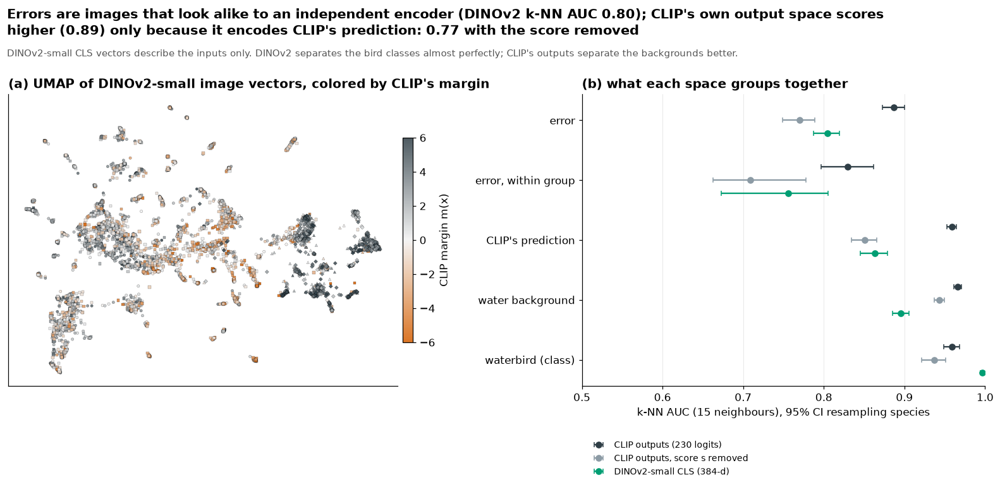

In [35]:
fig, (ax, bx) = plt.subplots(1, 2, figsize=(14.5, 6.2), gridspec_kw=dict(width_ratios=[1.15, 1]))
for g in style.GROUPS:
    d = df[df.group == g]
    sc = ax.scatter(d.dx, d.dy, c=d.margin, cmap=style.MARGIN_CMAP, norm=norm, s=8, marker=style.GROUP_MARKER[g],
                    lw=0.15, edgecolors="#00000040", alpha=0.85)
fig.colorbar(sc, ax=ax, shrink=0.7, pad=0.01).set_label("CLIP margin m(x)")
ax.set_xticks([]); ax.set_yticks([]); ax.grid(False); ax.set_title("(a) UMAP of DINOv2-small image vectors, colored by CLIP's margin")
PORDER = ["error", "error, within group", "CLIP's prediction", "water background", "waterbird (class)"]
SCOL = {"CLIP outputs (230 logits)": "#2F3E46", "CLIP outputs, score s removed": "#8C9BA5", "DINOv2-small CLS (384-d)": style.CUE_COLORS["bird"]}
yy = np.arange(len(PORDER))[::-1]
for k_, (sname, col) in enumerate(SCOL.items()):
    sub = kn[kn.space == sname].set_index("property").loc[PORDER]
    off = (1 - k_) * 0.22
    bx.errorbar(sub.auc, yy + off, xerr=[sub.auc - sub.lo, sub.hi - sub.auc], fmt="o", color=col, ms=6, capsize=2.5, label=sname)
bx.axvline(0.5, color="#222", ls=":", lw=1); bx.set_xlim(0.5, 1.0)
bx.set_yticks(yy, PORDER); bx.set_xlabel("k-NN AUC (15 neighbours), 95% CI resampling species")
bx.legend(loc="upper left", bbox_to_anchor=(0, -0.16), ncol=1, fontsize=9); bx.set_title("(b) what each space groups together"); bx.grid(axis="y", visible=False)
fig.tight_layout()
_c, _r, _d = "CLIP outputs (230 logits)", "CLIP outputs, score s removed", "DINOv2-small CLS (384-d)"
e_c, e_r, e_d = kn_i.loc["error", _c], kn_i.loc["error", _r], kn_i.loc["error", _d]
assert e_r < e_c - 0.05 and e_r <= e_d, "claims: removing the score drops the CLIP-space advantage below DINOv2"
assert kn_i.loc["waterbird (class)", _d] > kn_i.loc["waterbird (class)", _c] and kn_i.loc["water background", _c] > kn_i.loc["water background", _d], "claims about class vs background"
style.suptitle(fig, f"Errors are images that look alike to an independent encoder (DINOv2 k-NN AUC {e_d:.2f}); CLIP's own output space "
               f"scores higher ({e_c:.2f}) only because it encodes CLIP's prediction: {e_r:.2f} with the score removed",
               "DINOv2-small CLS vectors describe the inputs only. DINOv2 separates the bird classes almost perfectly; CLIP's outputs separate the backgrounds better.")
style.save(fig, "fig5d_dinov2_comparison"); plt.show()

**Checking the cluster descriptions.** The AI drafted short descriptions from the profile table and the thumbnails. Each description is split into testable parts, and every part is checked with **one fixed rule**:
- a named set of species (or a group) is **enriched ≥ 1.5×** in the cluster compared with all images (for landbird-only claims, compared with all landbirds)
- a "small bird" claim needs a median mask area < 0.9× the rest

Parts that fail are shown as *not supported* and left out of the finding. Caveat: descriptions were drafted and tested on the same data; there is no held-out set.

In [36]:
import re
def enrich(m, hit, base=None):
    base = np.ones(len(df), bool) if base is None else base
    a, b = hit[m & base].mean(), hit[base].mean()
    return a, b, (a / b if b > 0 else np.inf)
sp_has = lambda pat: df.species.str.contains(pat, regex=True).to_numpy()
is_lb = (df.label == 0).to_numpy()
DRAFT = {
    9: [("landbirds on water backgrounds", "group", "landbird / water"),
        ("mostly small drab species such as sparrows, larks and finches", "species", (r"Sparrow|Lark|Finch|Junco|Pipit", True))],
    3: [("small birds", "size", None),
        ("nightjars, wrens, creepers and kingfishers", "species", (r"Chuck_will|Nighthawk|Whip_poor|Wren|Creeper|Kingfisher", False))],
    4: [("the waterfowl region: real waterbirds here are almost always right, but landbirds here are almost always wrong", "lb_err", None),
        ("those landbirds are kingfishers, large woodpeckers and ravens", "species", (r"Kingfisher|Pileated|Red_cockaded|Red_headed|Raven", True))],
    1: [("bright yellow or orange songbirds", "species", (r"Warbler|Oriole|Goldfinch|Tanager|Yellowthroat|Yellow_breasted_Chat|Meadowlark", False))],
    0: [("all-black landbirds: crows, ravens, blackbirds, cowbirds, grackles", "species", (r"Crow|Raven|Blackbird|Cowbird|Grackle|Ani$|Starling", True)),
        ("next to dark seabirds: cormorants, albatrosses, frigatebirds", "species", (r"Cormorant|Albatross|Frigatebird", False))],
}
rows = []
for c in ecl:
    m = (df.cluster == c).to_numpy()
    for text, kind, arg in DRAFT.get(c, [("(no description drafted)", "none", None)]):
        if kind == "group":
            a, b, r = enrich(m, (df.group == arg).to_numpy()); ok = r >= 1.5
            test = f"{arg}: {pct(a)} in cluster vs. {pct(b)} overall ({r:.1f}×)"
        elif kind == "species":
            pat, lb_only = arg
            a, b, r = enrich(m, sp_has(pat), is_lb if lb_only else None); ok = r >= 1.5
            test = f"named species: {pct(a)} vs. {pct(b)} {'of landbirds' if lb_only else 'overall'} ({r:.1f}×)"
        elif kind == "size":
            a, b = df.mask_area[m].median(), df.mask_area[~m].median(); ok = a < 0.9 * b
            test = f"median bird area {pct(a)} vs. {pct(b)} in the rest"
        elif kind == "lb_err":
            lb_, wb_ = m & is_lb, m & ~is_lb
            a, w_ = 1 - df.correct[lb_].mean(), 1 - df.correct[wb_].mean(); ok = (a >= 0.9) and (w_ <= 0.05)
            test = f"{int(lb_.sum())} landbirds here, {pct(a)} wrong; {int(wb_.sum())} waterbirds, {pct(w_)} wrong"
        else:
            ok, test = False, "-"
        rows.append(dict(cluster=f"C{c}", claim=text, test=test, supported=bool(ok)))
checks = pd.DataFrame(rows)
display(checks)
not_drafted = [c for c in ecl if c not in DRAFT]
print("error clusters without a drafted description:", not_drafted)
dropped = [c for c in DRAFT if c not in ecl]
print("drafted descriptions whose cluster is no longer an error cluster (dropped):", [f"C{c}" for c in dropped])

,cluster,claim,test,supported
0,C3,small birds,median bird area 14.0% vs. 17.2% in the rest,True
1,C3,"nightjars, wrens, creepers and kingfishers",named species: 23.6% vs. 8.0% overall (2.9×),True
2,C4,the waterfowl region: real waterbirds here are...,"281 landbirds here, 96.8% wrong; 415 waterbird...",True
3,C4,"those landbirds are kingfishers, large woodpec...",named species: 29.9% vs. 6.5% of landbirds (4.6×),True
4,C9,landbirds on water backgrounds,landbird / water: 85.4% in cluster vs. 39.7% o...,True
5,C9,"mostly small drab species such as sparrows, la...",named species: 27.9% vs. 16.6% of landbirds (1...,True
6,C0,"all-black landbirds: crows, ravens, blackbirds...",named species: 56.7% vs. 8.4% of landbirds (6.8×),True
7,C0,"next to dark seabirds: cormorants, albatrosses...",named species: 7.5% vs. 3.4% overall (2.2×),True


error clusters without a drafted description: []
drafted descriptions whose cluster is no longer an error cluster (dropped): ['C1']


In [37]:
kn_i = kn.pivot(index="property", columns="space", values="auc")
def cl_line(c):
    r = clu.set_index("cluster").loc[c]
    ok = checks[(checks.cluster == f"C{c}") & checks.supported]
    bad = checks[(checks.cluster == f"C{c}") & ~checks.supported]
    s_ = f"- **C{c}** ({pct(r.err, 0)} wrong vs. {pct(r.expected, 0)} expected from its group mix, n = {int(r.n)}): " + ("; ".join(ok.claim) if len(ok) else "no supported description")
    s_ += f". Check: {'; '.join(ok.test)}." if len(ok) else "."
    if len(bad):
        s_ += f" *Not supported:* {'; '.join(bad.claim)} ({'; '.join(bad.test)})."
    return s_
lines = "\n".join(cl_line(c) for c in ecl)
md(f"""**Finding.** With k = {K} clusters found in the full 230-d output space (subsample ARI {ksel.set_index('k').loc[K, 'subsample_ARI']:.2f}, every cluster Jaccard ≥ {clu.jaccard.min():.2f}), {len(ecl)} clusters have clearly more errors than their class × background mix predicts:
{lines}

{('Dropped after the critique: ' + ', '.join(f'C{c}' for c in dropped) + ' had a high error rate only because of its group mix (it is mostly landbirds on water).') if dropped else ''}
Beyond the background, these clusters point to a third cue, **bird appearance**: all-black landbirds and the kingfishers, large woodpeckers and ravens that land in the waterfowl region are read as waterbirds whatever the dataset label says. Section 2 found the same kingfisher effect from the species ratings, so ecology and appearance are not separated here.
**Independent image space.** Errors are images that look alike to DINOv2 as well: k-NN AUC {kn_i.loc['error', _d]:.2f} ({kn_i.loc['error, within group', _d]:.2f} within groups). CLIP's own output space scores higher ({kn_i.loc['error', _c]:.2f}) only because it encodes CLIP's prediction: with the score removed it drops to {kn_i.loc['error', _r]:.2f}. DINOv2 separates the bird classes almost perfectly ({kn_i.loc['waterbird (class)', _d]:.3f}), CLIP's outputs separate the backgrounds better ({kn_i.loc['water background', _c]:.2f} vs. {kn_i.loc['water background', _d]:.2f}). So the information to tell the classes apart is in the images; CLIP's outputs weight the background more.""")

**Finding.** With k = 10 clusters found in the full 230-d output space (subsample ARI 0.90, every cluster Jaccard ≥ 0.75), 4 clusters have clearly more errors than their class × background mix predicts:
- **C3** (44% wrong vs. 23% expected from its group mix, n = 593): small birds; nightjars, wrens, creepers and kingfishers. Check: median bird area 14.0% vs. 17.2% in the rest; named species: 23.6% vs. 8.0% overall (2.9×).
- **C4** (40% wrong vs. 25% expected from its group mix, n = 696): the waterfowl region: real waterbirds here are almost always right, but landbirds here are almost always wrong; those landbirds are kingfishers, large woodpeckers and ravens. Check: 281 landbirds here, 96.8% wrong; 415 waterbirds, 1.0% wrong; named species: 29.9% vs. 6.5% of landbirds (4.6×).
- **C9** (59% wrong vs. 49% expected from its group mix, n = 717): landbirds on water backgrounds; mostly small drab species such as sparrows, larks and finches. Check: landbird / water: 85.4% in cluster vs. 39.7% overall (2.1×); named species: 27.9% vs. 16.6% of landbirds (1.7×).
- **C0** (39% wrong vs. 29% expected from its group mix, n = 509): all-black landbirds: crows, ravens, blackbirds, cowbirds, grackles; next to dark seabirds: cormorants, albatrosses, frigatebirds. Check: named species: 56.7% vs. 8.4% of landbirds (6.8×); named species: 7.5% vs. 3.4% overall (2.2×).

Dropped after the critique: C1 had a high error rate only because of its group mix (it is mostly landbirds on water).
Beyond the background, these clusters point to a third cue, **bird appearance**: all-black landbirds and the kingfishers, large woodpeckers and ravens that land in the waterfowl region are read as waterbirds whatever the dataset label says. Section 2 found the same kingfisher effect from the species ratings, so ecology and appearance are not separated here.
**Independent image space.** Errors are images that look alike to DINOv2 as well: k-NN AUC 0.80 (0.76 within groups). CLIP's own output space scores higher (0.89) only because it encodes CLIP's prediction: with the score removed it drops to 0.77. DINOv2 separates the bird classes almost perfectly (0.996), CLIP's outputs separate the backgrounds better (0.97 vs. 0.90). So the information to tell the classes apart is in the images; CLIP's outputs weight the background more.

**Limitation.** The 2-d UMAP layout is not stable across seeds and settings, so all structure is measured in the full 230-d space. The output vector depends on our prompt bank (200 species and 30 hand-written scene prompts). The 230 logits are a linear readout of CLIP's image embedding along 230 text directions. We treat them as outputs (they are what CLIP returns for 230 prompts), but they carry much of the embedding's information. The cluster descriptions were drafted by the AI and tested on the same data.

## 6. Interactive explorer

**Question.** Can one view connect the overview (where are the errors?), the species attribute (which birds?) and the experiment (which cue flips *this* bird?) so that a reader can check our findings on individual images?

**Data for the explorer.** All 5,794 test images (projection coordinates, margin, group, species, water rating, cluster, a 44 px thumbnail), per species summaries, and for the experiment birds their margins under every condition. For 150 birds per group we also embed a strip of 10 condition thumbnails. Thumbnails are WebP inside the HTML, so the file works offline.

In [38]:
from aivis.explorer_data import image_records, bird_records
STRIP_PER_GROUP = 150
rng_s = np.random.default_rng(3)
strip_idx = np.concatenate([rng_s.choice(df.loc[SAMPLE].index[df.loc[SAMPLE].group == g], STRIP_PER_GROUP, replace=False) for g in style.GROUPS])
IMG = image_records(df, CANV)
BIRDS = bird_records(CUE, THUMBS, strip_idx)
# curves on matching / conflicting plates: mean over all 10 plates of each type (follow-up run), not the single random plate
for role in ("matching", "conflicting"):
    curves = pd.concat({s_: plate_matrix(s_, role).mean(axis=1) for s_ in ex.SCALES}, axis=1)[ex.SCALES]
    for i, row in curves.iterrows():
        BIRDS[int(i)][f"paste_{'match' if role == 'matching' else 'conflict'}_all"] = [round(float(v), 2) for v in row]
SPEC = (df.groupby("species").agg(n=("correct", "size"), err=("correct", lambda c: round(1 - c.mean(), 3)),
                                  label=("label", "first"), rating=("water_rating", "first"),
                                  err_land=("correct", lambda c: np.nan), err_water=("correct", lambda c: np.nan)).reset_index())
for place, col in [(0, "err_land"), (1, "err_water")]:
    SPEC[col] = SPEC.species.map(df[df.place == place].groupby("species").correct.apply(lambda c: round(1 - c.mean(), 3)))
SPEC = SPEC.merge(rat[["species", "display_name", "reason"]], on="species", how="left")
desc_by_c = {int(c[1:]): "; ".join(g[g.supported].claim) for c, g in checks.groupby("cluster")}
CLUSTERS = [dict(id=int(r.cluster), n=int(r.n), err=round(float(r.err), 3), expected=round(float(r.expected), 3),
                 error_cluster=bool(r.error_cluster), description=desc_by_c.get(int(r.cluster), ""))
            for r in clu.sort_values("cluster").itertuples()]
SPEC = SPEC.replace({np.nan: None})
EXPLORER_DATA = dict(images=IMG, birds=BIRDS, species=SPEC.to_dict(orient="records"), clusters=CLUSTERS,
                     scales=ex.SCALES, sizes=ex.TEXT_SIZES, thumb_keys=[str(k) for k in THUMBS["keys"]],
                     overall_error=round(float(overall_err), 4))
size_mb = len(json.dumps(EXPLORER_DATA)) / 1e6
print(f"explorer data: {len(IMG)} images, {len(BIRDS)} experiment birds ({sum('thumbs' in b for b in BIRDS.values())} with strips), "
      f"{len(SPEC)} species, {size_mb:.1f} MB as JSON")

explorer data: 5794 images, 1200 experiment birds (600 with strips), 200 species, 12.3 MB as JSON


**Design.** At check-in 4 the AI proposed two designs: (A) linked Altair/Vega-Lite views, or (B) a custom single-file app in plain JavaScript with a canvas map. We chose **B** for richer interaction:
- **Map:** lasso selection, zoom and pan, and a switch between the CLIP-output map and the DINOv2 map (the same selection stays highlighted, so section 5's comparison can be explored directly).
- **Color:** margin, class, AI water rating, bird size or cluster. Shape always shows the group.
- **Selection summary:** error rate, group mix, top species.
- **Species:** a sortable table with the AI's rating reason on hover, and a species search.
- **Bird card:** for the clicked image. Birds from the experiment sample show 10 edited versions with their margins, plus their own dose-response curves for bird size and text size.

The file is fully offline: no CDN, data and WebP thumbnails are inlined. In Jupyter it is shown in an iframe below; if your notebook viewer blocks local iframes, open `outputs/explorer.html` directly in a browser.

In [39]:
from aivis.explorer_app import build_html
from IPython.display import IFrame
exp_path = build_html(EXPLORER_DATA, config.OUT_DIR / "explorer.html")
size_mb = exp_path.stat().st_size / 1e6
print(f"{exp_path.name}: {size_mb:.1f} MB")
assert size_mb < 20, "explorer must stay under about 20 MB"
IFrame(src=str(exp_path.relative_to(Path.cwd()).as_posix()), width="100%", height=1250)

explorer.html: 12.1 MB


## 7. Summary of findings and what Phase II should investigate

These findings went through a critique pass (check-in 5, AI log `09_critique.md`). Five independent AI reviewers and two verifiers found 7 high-severity problems in our first draft: wrong units in the CIs, one metric choice, a rule-ordered decomposition, unequal comparisons and a missing baseline. All 7 were fixed. One first-draft finding reversed ("two separate shortcuts"), one was reframed ("water scenes pull harder": the scene swing is symmetric, the asymmetry comes from CLIP's default), two were dropped ("'ocean' outweighs a real water scene", error cluster C1), and two shrank (label definition 15% → 4%; "errors cluster in CLIP's outputs" was mostly self-prediction).

In [40]:
md(f"""### Findings (every number from a cell above; CIs resample species, and plates where scenes are involved)
1. **The background is the main driver, and a label bug inflated one group.** With corrected labels, landbirds are right {pct(lb_l.acc)} of the time on land but only {pct(lb_w.acc)} [{pct(lb_w.lo)}, {pct(lb_w.hi)}] on water. The "tern" substring rule in the original data script mislabels 3 landbird species. Fixing it moves waterbirds on water from {pct(o_wbw.acc)} to {pct(wb_w.acc)}. Of all {n_err:,} errors, {pct(share['background excess'])} [{pct(share_ci.loc['background excess', 'lo'])}, {pct(share_ci.loc['background excess', 'hi'])}] are background excess over the matched-habitat error rate.
2. **The label definition matters for 5 species, not for water-tied landbirds in general.** The 4 American kingfishers and Louisiana Waterthrush are wrong {pct(e3l.err)} of the time even on land backgrounds (vs. {pct(e0l.err)} for dry-land species, permutation p = {PV[('land', 3)]:.4f}). Marsh landbirds (rating 2) are not distinguishable from dry-land species (p = {PV[('land', 2)]:.2f}). As excess risk, the definition explains {pct(share['definition excess'])} of the errors and the tern bug {pct(share['label bug'])}. The species ratings are AI-derived; the human check is {'done (' + str(hc_stats['n']) + ' species, κ = ' + format(hc_stats['kappa_w'], '.2f') + ')' if hc_stats else 'still pending'}.
3. **The shortcut is not in the word "waterbird".** No rewording weakens the background effect (background AUC {b0.bg_auc:.2f} → {dsub.bg_auc.min():.2f}-{dsub.bg_auc.max():.2f}). Routing through 200 species names keeps the background effect ({r0.bg_auc:.2f}) but sharpens the bird evidence (class AUC {b0.class_auc:.2f} → {r0.class_auc:.2f}), lifting the worst group from {pct(wide.loc['baseline', 'worst group'])} to {pct(wide.loc['species routing (hard)', 'worst group'])}.
4. **CLIP adds up bird and background; scenes act symmetrically; words dominate.** In the controlled experiment ({len(W)} birds, {len(CUE) + len(CUE2):,} edited images):
   - **Additive.** The water score is roughly the sum of bird and background evidence (R² = {r2:.2f}). The bird wins {pct(fbird[0])} of conflicts. The fitted boundary leans {coef[2]:.2f} logits towards "waterbird".
   - **Symmetric scenes.** Swapping a land scene for a water scene moves both classes by the same amount ({d_lb.loc[0.5, 'swing']:.2f} vs. {d_wb.loc[0.5, 'swing']:.2f} logits). Landbirds fail more because CLIP's default leans "waterbird": a small landbird on plain gray already gets s = +{g15.gray_s:.2f}.
   - **Words.** Dose-matched on the same base, a misleading word at 4% height flips {pct(w4.share.min())}-{pct(w4.share.max())} of correct birds; a conflicting real scene flips {pct(scn.share.min())}-{pct(scn.share.max())}. "waterbird" moves the score {ratio[0]:.1f}× [{ratio[1]:.1f}, {ratio[2]:.1f}] as far as a real water scene. Even random letter strings push towards water (up to +{ctrl_rng[1]:.2f}).
   - **One shared weakness.** Birds fooled by scenes are also fooled by words (ρ = {RHO[(0, 'fooled')][0]:.2f} / {RHO[(1, 'fooled')][0]:.2f}): weakly recognised birds are vulnerable to both cues.
5. **A third cue: bird appearance.** In CLIP's output space, {len(ecl)} stable clusters have more errors than their bird/background mix predicts. Among them, all-black landbirds and the kingfishers, large woodpeckers and ravens in the waterfowl region are read as waterbirds. The error images also look alike to an independent encoder (DINOv2 k-NN AUC {kn_i.loc['error', _d]:.2f}). CLIP's own output space only scores higher because it encodes CLIP's prediction ({kn_i.loc['error', _c]:.2f}, {kn_i.loc['error', _r]:.2f} with the score removed).""")

### Findings (every number from a cell above; CIs resample species, and plates where scenes are involved)
1. **The background is the main driver, and a label bug inflated one group.** With corrected labels, landbirds are right 87.5% of the time on land but only 45.1% [41.5%, 48.6%] on water. The "tern" substring rule in the original data script mislabels 3 landbird species. Fixing it moves waterbirds on water from 96.0% to 99.2%. Of all 1,706 errors, 61.7% [56.8%, 66.5%] are background excess over the matched-habitat error rate.
2. **The label definition matters for 5 species, not for water-tied landbirds in general.** The 4 American kingfishers and Louisiana Waterthrush are wrong 49.4% of the time even on land backgrounds (vs. 11.8% for dry-land species, permutation p = 0.0001). Marsh landbirds (rating 2) are not distinguishable from dry-land species (p = 0.40). As excess risk, the definition explains 4.3% of the errors and the tern bug 3.4%. The species ratings are AI-derived; the human check is still pending.
3. **The shortcut is not in the word "waterbird".** No rewording weakens the background effect (background AUC 0.81 → 0.87-0.92). Routing through 200 species names keeps the background effect (0.81) but sharpens the bird evidence (class AUC 0.91 → 0.96), lifting the worst group from 45.1% to 68.3%.
4. **CLIP adds up bird and background; scenes act symmetrically; words dominate.** In the controlled experiment (1200 birds, 361,200 edited images):
   - **Additive.** The water score is roughly the sum of bird and background evidence (R² = 0.83). The bird wins 65.4% of conflicts. The fitted boundary leans 0.31 logits towards "waterbird".
   - **Symmetric scenes.** Swapping a land scene for a water scene moves both classes by the same amount (2.14 vs. 2.18 logits). Landbirds fail more because CLIP's default leans "waterbird": a small landbird on plain gray already gets s = +0.44.
   - **Words.** Dose-matched on the same base, a misleading word at 4% height flips 89.4%-100.0% of correct birds; a conflicting real scene flips 15.5%-97.1%. "waterbird" moves the score 3.2× [2.4, 4.9] as far as a real water scene. Even random letter strings push towards water (up to +0.95).
   - **One shared weakness.** Birds fooled by scenes are also fooled by words (ρ = 0.39 / 0.32): weakly recognised birds are vulnerable to both cues.
5. **A third cue: bird appearance.** In CLIP's output space, 4 stable clusters have more errors than their bird/background mix predicts. Among them, all-black landbirds and the kingfishers, large woodpeckers and ravens in the waterfowl region are read as waterbirds. The error images also look alike to an independent encoder (DINOv2 k-NN AUC 0.80). CLIP's own output space only scores higher because it encodes CLIP's prediction (0.89, 0.77 with the score removed).

### What Phase II should investigate (opening the black box)
1. **One shared weakness.** Birds that are weakly recognised are vulnerable to both scenes and words (section 4c). Inside the image encoder, is "weak bird evidence" visible as low attribution on the bird? Compare saliency or attention maps for birds that are fooled by both cues vs. robust birds.
2. **Why does CLIP's default lean "waterbird"?** Plain gray, small birds and random letter strings all push towards water (sections 4d-4f). Probe the image embeddings of gray, blank-box and text-only images against the two class prompts.
3. **Why do species names carry more bird evidence than "waterbird"?** Compare where the text embeddings of the class words and the 200 species names sit relative to image embeddings of birds on gray (section 3).
4. **The appearance cue.** Do black plumage and kingfisher/woodpecker shapes activate the same features as cormorants and auks? Use saliency and nearest neighbours in the image-embedding space on clusters C0 and C4 (section 5).
5. **Text reading.** Misspelled and random strings push towards "waterbird". Which features of the image encoder respond to text, and do they overlap with scene features?

For the joint discussion with the human-only pair: their typographic-attack results (different placement, one size) agree in direction with section 4.

In [41]:
print(f"notebook runtime: {(time.time() - T0) / 60:.1f} min (with the cache in {config.CACHE_DIR})")
print("figures written to outputs/:", sorted(p.name for p in config.OUT_DIR.glob("*.png")))

notebook runtime: 3.5 min (with the cache in C:\Users\medo\aivis_cache)
figures written to outputs/: ['fig1_baseline_label_audit.png', 'fig2a_error_vs_water_rating.png', 'fig2b_error_decomposition.png', 'fig3_prompt_strategies.png', 'fig3b_fixed_broken.png', 'fig4_qc_conditions.png', 'fig4_qc_masks_random.png', 'fig4_qc_masks_rejected.png', 'fig4_qc_plates.png', 'fig4_qc_plates_rejected_attempt.png', 'fig4a_cue_quadrant.png', 'fig4b_dose_response.png', 'fig4c_background_vs_text_resistance.png', 'fig4d_word_vs_scene.png', 'fig4e_scene_asymmetry.png', 'fig4f_word_vs_scene_dose_matched.png', 'fig5_projection_clip_outputs.png', 'fig5b_projection_stability.png', 'fig5c_error_cluster_members.png', 'fig5d_dinov2_comparison.png']
